
# Week 11 — Security, Compliance & Responsible AI in Production

This notebook has **four independent demo blocks**. Every block is self-contained, so you can run any single block without running the others first (after running the Setup cell once).

| Block | Topic | What you will see | Dataset |
|---|---|---|---|
| **1** | Model Security | Model theft, privacy leaks, poisoned data, strange inputs, abusive traffic | Breast Cancer Wisconsin (scikit-learn) |
| **2** | Data Privacy | How easily people can be re-identified, and how anonymisation helps | Adult Income (UCI, via the `shap` library) |
| **3** | Responsible AI | Hidden unfairness inside a good accuracy score, and explaining model decisions with SHAP | NHANES-I Health Survey (via the `shap` library) |
| **4** | Case Study | Drift, fairness gaps after drift, and a fairness-constrained retrain | Diabetes (scikit-learn) |

**Note on datasets:** the session plan called for the German Credit dataset in Block 3. That dataset is hosted on the UCI repository and OpenML, which are not reachable from this environment's network allowlist. NHANES-I (a real health survey with age and sex attributes, bundled with the `shap` library) is used instead. It supports the same fairness + explainability workflow on real data.

**Libraries needed:** pandas, numpy, scikit-learn, fairlearn, shap, joblib, matplotlib, ipywidgets. If one is missing, install it with `pip install <name>`.

### How to read each section
Every demo follows the same pattern:

| Part | What you will find |
|---|---|
| 🎯 **The idea** | What the attack, risk or technique is, with an everyday analogy |
| **Step 1, Step 2, ...** | Each step names what it does, lists **what we will do**, shows **the code** and explains **how to read the result** |
| 🛡️ **Defences / takeaways** | What to do about it in real systems |

### Core glossary (keep this handy; each block adds a few more terms)
| Term | Plain-English meaning |
|---|---|
| **Model** | A program that learned patterns from past examples so it can make predictions on new ones |
| **Features** | The input columns the model looks at (e.g. age, blood pressure, tumour size) |
| **Label** | The correct answer we want to predict (e.g. benign or malignant) |
| **Training data** | Examples the model is allowed to learn from |
| **Test data (held-out)** | Examples hidden from the model during learning, used to check how well it does on *new* cases |
| **Accuracy** | Share of predictions that were correct (0.95 = 95 % right) |
| **API (black box)** | A service you can send questions to and get answers from, without seeing what is inside |
| **Attacker** | Someone trying to misuse, copy, or break the model |


## Setup — Environment

### 🎯 The idea
Before any demo, we need to (1) load the Python libraries (toolboxes) we will use and (2) pick a consistent colour palette so every chart in the notebook looks the same.

**What we will do**
1. Turn off noisy warning messages so beginners are not distracted.
2. Import the libraries: `numpy` (maths on arrays), `pandas` (tables), `matplotlib` (charts).
3. Define five named colours.
4. Tell matplotlib to use those colours and a clean white style for all charts.
5. Print a confirmation message.

In [1]:
# Environment check — run this first

import warnings  # built-in Python tool for controlling warning messages
warnings.filterwarnings("ignore")  # hide warnings so the output stays clean and easy to read

import numpy as np  # numpy = fast maths on numbers/arrays; "np" is the usual short nickname
import pandas as pd  # pandas = tables of data (called DataFrames); "pd" is the usual nickname
import matplotlib.pyplot as plt  # matplotlib's plotting module; we use it to draw charts
import matplotlib as mpl  # the main matplotlib module; we use it to set global chart styles

# Consistent visual style across all four blocks
NAVY = "#0B2545"        # dark blue: used for text, axes titles and reference lines
TEAL = "#1C7293"        # teal: used for "normal / safe / good" things in charts
TEAL_LIGHT = "#4FA9C9"  # lighter teal: a spare accent colour
ALERT = "#D9724C"       # orange-red: used for "attack / risky / warning" things in charts
MUTED = "#6E85A3"       # grey-blue: used for chart borders and neutral items

mpl.rcParams["figure.facecolor"] = "white"   # the outer background of every figure is white
mpl.rcParams["axes.facecolor"] = "white"     # the plotting area inside the axes is white too
mpl.rcParams["axes.edgecolor"] = MUTED       # the box lines around each chart use the muted colour
mpl.rcParams["axes.labelcolor"] = NAVY       # axis labels (e.g. "Accuracy") are navy
mpl.rcParams["text.color"] = NAVY            # any other text on a chart is navy
mpl.rcParams["xtick.color"] = NAVY           # the little numbers along the x-axis are navy
mpl.rcParams["ytick.color"] = NAVY           # the little numbers along the y-axis are navy
mpl.rcParams["axes.titlecolor"] = NAVY       # chart titles are navy
mpl.rcParams["font.size"] = 11               # default text size for all charts

print("Environment ready.")  # confirm that the setup cell ran successfully

Environment ready.


**How to read the result**
You should see just one line: `Environment ready.` Nothing else should appear. If you see an error such as `ModuleNotFoundError`, a library is missing; install it (for example `pip install pandas`) and re-run the cell.

---
## Block 1 — Model Security: the big picture

**Dataset:** Breast Cancer Wisconsin — 569 patient records, 30 numeric measurements each, and a binary diagnosis (malignant or benign). It is built into scikit-learn, so no download is needed.

### Why does a model need "security" at all?
A trained model is a valuable asset. It can leak private information, be copied, be tricked, or be corrupted, just like any other software system. In this block we simulate **one realistic attack or defence for each of four threat buckets**:

| # | Threat bucket | What can go wrong | Demo in this notebook |
|---|---|---|---|
| 1.1 + 1.2 | **Model & privacy threats** | Someone copies your model, or works out who was in your training data | Model extraction attack and membership inference |
| 1.3 | **Data threats** | Bad or tampered training data quietly ruins the model | Label poisoning |
| 1.4 | **Input threats** | Strange inputs the model was never built to handle | Out-of-distribution (OOD) detector |
| 1.5 | **Infrastructure & access threats** | Abuse of the serving system itself | Query-rate anomaly detector |

> 💡 **Tip:** the same "victim" model is used throughout, so the story builds from one demo to the next.

## Baseline model — build the "victim"

### 🎯 The idea
Before we can attack anything, we need something worth attacking. We train a normal, well-behaved model that predicts whether a tumour is malignant or benign. Think of this as **the company's secret product** that the attacker will later try to copy.

**What we will do**
1. Load the breast-cancer dataset into a table (`X` = measurements, `y` = diagnosis).
2. **Split** the data: 75 % for training, 25 % hidden away for testing. Why? A student who memorises the exam answers will look brilliant on the practice paper but may fail a new paper, so we need a "new paper" to check honesty.
3. Create a **Random Forest**: a crowd of 200 small decision trees that vote together on each answer.
4. **Train** (`fit`) it on the training data only.
5. Measure accuracy on the training data *and* on the hidden test data.
6. **Save** the trained model to a file, so later demos can load it exactly like a deployed production model.

**The code**

In [2]:
from sklearn.datasets import load_breast_cancer  # built-in example dataset: breast cancer measurements
from sklearn.model_selection import train_test_split  # helper that splits data into train and test parts
from sklearn.ensemble import RandomForestClassifier  # our model type: many decision trees voting together
from sklearn.tree import DecisionTreeClassifier  # a single decision tree; the attacker will use it later
from sklearn.metrics import accuracy_score  # function that calculates "what share of predictions were right"
import joblib  # tool for saving a trained model to disk and loading it back later

data = load_breast_cancer(as_frame=True)  # load the dataset; as_frame=True gives us pandas tables
X, y = data.data, data.target  # X = the 30 measurement columns (features), y = the diagnosis (label)

X_train, X_test, y_train, y_test = train_test_split(  # split the data into a training set and a test set
    X, y, test_size=0.25, stratify=y, random_state=42  # 25% goes to testing; stratify keeps the benign/malignant mix equal in both; random_state=42 makes the split repeatable
)

baseline_model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)  # create a forest of 200 trees, each at most 6 questions deep
baseline_model.fit(X_train, y_train)  # TRAIN: the model learns patterns linking measurements to diagnoses

train_acc = accuracy_score(y_train, baseline_model.predict(X_train))  # accuracy on data the model has already seen
test_acc = accuracy_score(y_test, baseline_model.predict(X_test))  # accuracy on hidden data the model has never seen

joblib.dump(baseline_model, "breast_cancer_baseline.joblib")  # save the trained model to a file, like "deploying" it

print(f"Training accuracy: {train_acc:.3f}")  # show training accuracy, rounded to 3 decimals
print(f"Held-out test accuracy: {test_acc:.3f}")  # show test accuracy, rounded to 3 decimals
print(f"Feature count: {X.shape[1]}")  # X.shape[1] = number of columns = number of features (30)

Training accuracy: 0.998
Held-out test accuracy: 0.958
Feature count: 30


**How to read the result**
- **Training accuracy** is usually a little higher than **test accuracy**, and that is normal. The model has seen the training rows, but the test rows are new to it.
- **Test accuracy is the number that matters.** It shows how well the model works on new patients. We will compare later results against it.
- **Feature count: 30** confirms each patient is described by 30 measurements.
- 📌 **Remember `train_acc` vs `test_acc`.** The gap between them becomes the secret weakness exploited in Section 1.2 (membership inference).

---
## 1.1 — Model & privacy threats: a model extraction attack

### 🎯 The idea
**Model extraction** means copying someone's model **without ever seeing inside it**.

> 🍝 **Analogy:** Imagine a restaurant with a secret recipe. You cannot enter the kitchen, but you can order 1,500 different dishes and taste each one. After enough tastings you can cook something that tastes almost identical, without ever seeing the recipe.

Here the "restaurant" is a deployed model behind an API, the "orders" are queries, and the "tastings" are the predictions that come back. The attacker uses those input→output pairs to train a **surrogate (copy) model**.

### Why this matters
- The attacker steals the intellectual property that cost you time and money to build.
- A copy lets them study your model offline, find its weak spots, and attack it more cleverly.

### Step 1: Set the scene and craft the queries

**What we will do**
1. Load the saved model and pretend it is a live service. Define `deployed_model_query()`, the **only door** the attacker can use.
2. Remember which attacker knowledge is allowed: no weights, no training data, no labels, only the right to ask questions.
3. Generate 1,500 realistic-looking fake inputs. Pure random noise would be easy to spot, so for each feature column the attacker randomly re-uses plausible values (for example, from public summary statistics).

**The code**

In [3]:
deployed_model = joblib.load("breast_cancer_baseline.joblib")  # load the saved model, as if it were running on a production server
feature_names = X.columns.tolist()  # list of the 30 column names; we reuse it to build fake inputs

def deployed_model_query(X_query):  # the ONLY way the attacker can talk to the model (a black-box API)
    """Simulates calling a deployed model's prediction API."""  # a docstring = a short description of what the function does
    return deployed_model.predict(X_query)  # send inputs in, get predicted labels (0 or 1) back; nothing else is revealed

# --- Attacker's side: no access to training data or labels, only to the query API ---
# The attacker samples plausible-looking inputs by bootstrapping each feature's marginal
# distribution independently (e.g. from public summary statistics) — far more realistic
# than pure uniform-random noise, and much more damaging.
rng = np.random.default_rng(7)  # create a random-number generator; seed 7 makes results repeatable for everyone
N_QUERIES = 1500  # how many questions the attacker will send to the API

synthetic_queries = pd.DataFrame(  # build a table of fake query inputs
    {col: rng.choice(X_train[col].values, N_QUERIES, replace=True) for col in feature_names}  # for EACH column, randomly pick 1,500 realistic values (replace=True lets a value repeat)
)
synthetic_queries.head()  # show the first 5 rows so you can see what the fake queries look like

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,15.610,20.28,97.65,402.0,0.09159,0.18020,0.077210,0.04489,0.1781,0.05629,...,21.580,17.58,114.20,274.9,0.1195,0.1997,0.40000,0.08150,0.3274,0.06623
1,12.900,20.76,131.20,645.7,0.08759,0.06630,0.005067,0.13100,0.1788,0.07285,...,14.060,24.85,108.60,440.4,0.1640,0.3511,0.76810,0.09391,0.2592,0.08677
2,9.904,18.15,97.26,869.5,0.09056,0.07255,0.046350,0.04744,0.1962,0.05541,...,14.920,33.58,88.54,1321.0,0.1220,0.3627,0.13970,0.06042,0.2741,0.06120
3,11.750,26.86,75.17,514.5,0.09373,0.07838,0.012060,0.02180,0.2057,0.06714,...,9.077,21.75,65.74,648.3,0.1223,0.4370,0.09915,0.00000,0.3215,0.08523
4,12.190,19.86,64.41,317.5,0.10300,0.16450,0.203000,0.03965,0.3040,0.05541,...,14.190,33.15,104.40,591.2,0.1166,0.1575,0.01335,0.13740,0.2901,0.06386


**How to read the result**
You will see a table of 5 rows × 30 columns. These are **fake patients** invented by the attacker. Each column's values look realistic, but the *combinations* are random, so these are not real people. They are just good enough to make the model respond sensibly.

### Step 2: Steal the answers and train a copy

**What we will do**
1. Send all 1,500 fake patients to the API and record the predictions. These are the **stolen labels**.
2. Create a fresh, simple **Decision Tree**, which is the attacker's own model.
3. Train it using *only* the fake inputs and the stolen answers.

**The code**

In [4]:
stolen_labels = deployed_model_query(synthetic_queries)  # ask the deployed model to label all 1,500 fake patients; the answers are "stolen"

surrogate_model = DecisionTreeClassifier(max_depth=6, random_state=42)  # the attacker's own copycat model: a single decision tree
surrogate_model.fit(synthetic_queries, stolen_labels)  # train the copy using ONLY fake inputs + the victim's answers

print(f"Queries sent to the API: {N_QUERIES}")  # report how many queries the attack needed
print("Surrogate model trained on stolen input-output pairs only.")  # confirm that no real training data was used

Queries sent to the API: 1500
Surrogate model trained on stolen input-output pairs only.


**How to read the result**
Nothing impressive is printed here, and that is the point: the theft was **silent**. From the API's point of view this looked like ordinary usage. The next step reveals how good the copy is.

### Step 3: Measure how good the copy is

**What we will do**
1. Ask **both** models (the original and the copy) to predict the same real test patients.
2. **Fidelity** = how often the copy gives the *same answer as the original*. This is the attacker's success score.
3. Also check the copy's accuracy against the *true* diagnoses, and compare with the original's accuracy.

**The code**

In [5]:
surrogate_predictions = surrogate_model.predict(X_test)  # the copycat model's answers on real, unseen test patients
target_predictions = deployed_model_query(X_test)  # the original (victim) model's answers on the same patients

fidelity = accuracy_score(target_predictions, surrogate_predictions)  # how often copy == original (agreement rate)
surrogate_real_world_acc = accuracy_score(y_test, surrogate_predictions)  # how often the copy matches the TRUE diagnosis

print(f"Surrogate vs. target agreement (fidelity): {fidelity:.1%}")  # % of cases where the copy agrees with the original
print(f"Surrogate accuracy on real held-out labels:  {surrogate_real_world_acc:.1%}")  # copy's real-world accuracy
print(f"Original model accuracy on the same data:    {test_acc:.1%}")  # original's real-world accuracy, from the baseline model
print()  # print a blank line for readability
print("Interpretation: the attacker never saw a single real training record or label, only")  # explanation line 1
print(f"{N_QUERIES} query responses — yet the surrogate model matches the deployed model's")  # explanation line 2 (inserts the query count)
print("predictions on unseen data almost exactly. This is what makes rate limiting, output")  # explanation line 3
print("perturbation, and query-pattern monitoring necessary defenses, not optional ones.")  # explanation line 4

Surrogate vs. target agreement (fidelity): 99.3%
Surrogate accuracy on real held-out labels:  95.1%
Original model accuracy on the same data:    95.8%

Interpretation: the attacker never saw a single real training record or label, only
1500 query responses — yet the surrogate model matches the deployed model's
predictions on unseen data almost exactly. This is what makes rate limiting, output
perturbation, and query-pattern monitoring necessary defenses, not optional ones.


**How to read the result**
| Number | What it tells you |
|---|---|
| **Fidelity** | The closer to 100 %, the better the attacker's copy mimics your model. High fidelity = **successful theft** |
| **Surrogate accuracy** | How well the stolen copy performs on real data, with no real training data needed |
| **Original accuracy** | The benchmark. If the copy is close to this, the attacker has effectively got your model for free |

**Key takeaway:** the attacker needed **only 1,500 questions** and no inside access. A model that answers unlimited questions for free can be cloned.

**🛡️ Defences:** rate limiting (cap queries per user), output perturbation (add slight noise or round outputs), query-pattern monitoring (see Section 1.5), and returning labels only rather than detailed probabilities.

---
## 1.2 — Membership inference: does the model "remember" its training data?

### 🎯 The idea
**Membership inference** asks: *"Was this specific person's record used to train the model?"* If an attacker can answer that, privacy is broken. Learning that someone's record is in a **cancer-patient dataset** reveals sensitive health information about them.

> 📝 **Analogy:** A student who memorised last year's exam answers is **extra confident** on those exact questions and hesitant on new ones. By watching how confident the student is, you can guess which questions they have seen before.

Models behave the same way: they tend to be **more confident on data they were trained on** than on data they have never seen. That confidence gap is the leak.

### Step 1: Confidence gap

**What we will do**
1. For every training record and every test record, ask the model for its **confidence** (the highest class probability, e.g. "97 % sure it is benign").
2. Compare the average confidence for **members** (training data) and **non-members** (unseen data).
3. Draw a histogram of both. If the two shapes differ, the model leaks membership information.

**The code**

Mean confidence on TRAINING records: 0.966
Mean confidence on HELD-OUT records:  0.935


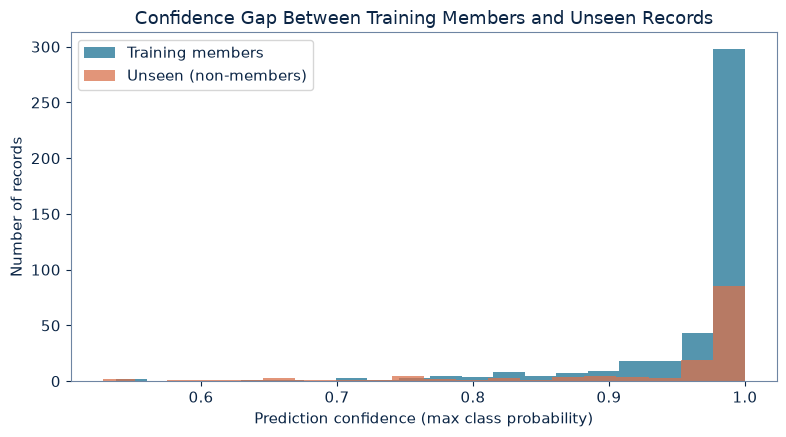

In [6]:
train_confidence = baseline_model.predict_proba(X_train).max(axis=1)  # for each TRAINING row: probability of each class, then keep the highest one (the model's confidence)
test_confidence = baseline_model.predict_proba(X_test).max(axis=1)  # same calculation for the unseen TEST rows

print(f"Mean confidence on TRAINING records: {train_confidence.mean():.3f}")  # average confidence on rows the model has seen
print(f"Mean confidence on HELD-OUT records:  {test_confidence.mean():.3f}")  # average confidence on rows it has never seen

fig, ax = plt.subplots(figsize=(8, 4.5))  # create an empty chart canvas (8 inches wide, 4.5 inches tall)
ax.hist(train_confidence, bins=20, alpha=0.75, color=TEAL, label="Training members")  # histogram of confidences for training rows (alpha = see-through)
ax.hist(test_confidence, bins=20, alpha=0.75, color=ALERT, label="Unseen (non-members)")  # histogram for unseen rows, drawn on the same chart
ax.set_xlabel("Prediction confidence (max class probability)")  # label under the x-axis
ax.set_ylabel("Number of records")  # label beside the y-axis
ax.set_title("Confidence Gap Between Training Members and Unseen Records")  # chart title
ax.legend()  # show the colour key (which colour = members / non-members)
plt.tight_layout()  # adjust spacing so labels are not cut off
plt.show()  # draw the chart on screen

**How to read the result**
- **Teal bars (training members)** bunch up near **1.0**: the model is almost certain about rows it studied.
- **Orange bars (unseen records)** are more spread out, with more medium-confidence answers.
- **The more the two shapes differ, the easier it is for an attacker to tell "member" from "non-member"** just by looking at confidence.

### Step 2: Attack score (AUC)

**What we will do**
1. Build a "scoreboard": label training rows `1` (member) and test rows `0` (non-member).
2. Use the model's confidence as the attacker's **guess score** (higher confidence → "probably a member").
3. Calculate **AUC**, a single number from 0.5 to 1.0 that shows how well the guess separates members from non-members:
   - **0.5** = pure coin-flip, no leakage
   - **1.0** = perfect leakage
4. Also try a simple rule: *"if confidence is above 0.99, say member"*, and see how often it is right.

**The code**

In [7]:
from sklearn.metrics import roc_auc_score  # function that computes AUC (how well scores separate two groups)

labels_membership = np.concatenate([np.ones(len(train_confidence)), np.zeros(len(test_confidence))])  # ground truth: 1 for every training row (member), 0 for every test row (non-member)
scores_membership = np.concatenate([train_confidence, test_confidence])  # the attacker's evidence: one confidence score per row, in the same order as the labels
attack_auc = roc_auc_score(labels_membership, scores_membership)  # AUC of the attack: 0.5 = random guessing, 1.0 = perfect

threshold = 0.99  # simple rule: confidence above 99% is declared "member"
attack_predictions = (scores_membership > threshold).astype(int)  # apply the rule: True/False converted to 1 (member) / 0 (non-member)
attack_accuracy = (attack_predictions == labels_membership).mean()  # share of rows where the attacker's guess matched the truth

print(f"Membership inference attack AUC:        {attack_auc:.3f}  (0.5 = no leakage, 1.0 = full leakage)")  # report AUC with its scale
print(f"Attack accuracy at confidence > {threshold}: {attack_accuracy:.1%}")  # report the simple-rule accuracy
print()  # blank line for readability
print("An AUC meaningfully above 0.5 confirms the model leaks membership information.")  # interpretation line 1
print("Defenses: differential privacy during training, regularization, confidence rounding.")  # list of fixes

Membership inference attack AUC:        0.587  (0.5 = no leakage, 1.0 = full leakage)
Attack accuracy at confidence > 0.99: 58.3%

An AUC meaningfully above 0.5 confirms the model leaks membership information.
Defenses: differential privacy during training, regularization, confidence rounding.


**How to read the result**
| Number | Meaning |
|---|---|
| **AUC ≈ 0.5** | The attacker is guessing. The model is not leaking much. |
| **AUC clearly above 0.5** | The attacker can tell members from non-members, so **privacy is leaking**. |
| **Our run: AUC ≈ 0.59** | A **mild but real** leak (better than a coin-flip). It is modest here because the dataset is small and the forest is shallow (max depth 6). Larger or more overfit models usually leak more. |
| **Attack accuracy** | With one simple rule, how often the attacker correctly says "member / not member". ⚠️ The scoreboard is **not balanced**: about 75 % of rows are members. So an attacker who *always* says "member" would already score about 75 %. This is why **AUC is the more reliable number** here, and why a figure like 58 % should not be read as "better than chance". |

**Why it happens:** the model fits its training data very closely (overfitting), so its behaviour on training rows is different from its behaviour on new rows.

**🛡️ Defences, in plain words:**
- **Differential privacy:** add carefully measured noise during training so no single record leaves a fingerprint.
- **Regularization:** stop the model from memorising (e.g. shallower trees, less complex models).
- **Confidence rounding:** do not reveal exact probabilities, only coarse ones or just the label.

---
## 1.3 — Data threats: poisoning training data with label noise

### 🎯 The idea
**Data poisoning** means corrupting the data a model learns from, so the model learns the wrong lessons.

> 📚 **Analogy:** If a student's textbook has some wrong answers printed in it, the student will confidently learn wrong facts. The more mistakes in the book, the worse the student does in the real exam.

Poisoning can be deliberate (an attacker flips labels) or accidental (a low-quality labelling team). Either way, the damage is the same. In this demo we **flip a growing share of training labels** (benign ↔ malignant) and measure how much accuracy suffers.

### Step 1: Poison the labels and measure accuracy

**What we will do**
1. Write a helper function `poison_labels()` that randomly flips a chosen percentage of labels.
2. Choose noise levels to test: 0 %, 5 %, 10 %, 20 %, 30 %.
3. For **each** level: corrupt the training labels, **train a fresh model from scratch**, and test it on the **clean** test set.
4. Collect the accuracies so we can chart them.

**The code**

In [8]:
def poison_labels(y, poison_rate, seed=0):  # function: takes true labels and returns a corrupted copy
    rng_local = np.random.default_rng(seed)  # a private random generator so each run flips the same rows (repeatable)
    y_poisoned = y.copy().reset_index(drop=True) if hasattr(y, "reset_index") else np.array(y).copy()  # make a safe copy so the ORIGINAL labels are never changed
    n_flip = int(len(y_poisoned) * poison_rate)  # how many labels to flip (e.g. 10% of 426 rows = 42)
    flip_idx = rng_local.choice(len(y_poisoned), size=n_flip, replace=False)  # randomly pick which rows to corrupt (no row picked twice)
    y_poisoned = np.array(y_poisoned)  # convert to a plain array so we can edit values by position
    y_poisoned[flip_idx] = 1 - y_poisoned[flip_idx]  # FLIP: 0 becomes 1 and 1 becomes 0 for the chosen rows
    return y_poisoned  # hand back the corrupted labels

poison_rates = [0.0, 0.05, 0.10, 0.20, 0.30]  # the noise levels to test, from 0% (clean) to 30% (heavily corrupted)
poisoned_accuracies = []  # empty list: we will store the accuracy for each noise level here

for rate in poison_rates:  # repeat the steps below once for each noise level
    y_train_poisoned = poison_labels(y_train, rate, seed=42)  # corrupt the training labels at this noise level
    poisoned_model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)  # create a brand-new model with the SAME settings as the baseline
    poisoned_model.fit(X_train, y_train_poisoned)  # train it on clean inputs but corrupted labels
    acc = accuracy_score(y_test, poisoned_model.predict(X_test))  # test on CLEAN test labels, which shows the real damage
    poisoned_accuracies.append(acc)  # save this accuracy for the chart
    print(f"Label noise rate {rate:.0%}: held-out accuracy = {acc:.3f}")  # print the noise level and its accuracy

Label noise rate 0%: held-out accuracy = 0.958
Label noise rate 5%: held-out accuracy = 0.958
Label noise rate 10%: held-out accuracy = 0.965
Label noise rate 20%: held-out accuracy = 0.944
Label noise rate 30%: held-out accuracy = 0.909


**How to read the result**
Read the printed lines from top to bottom. The **0 % line is the clean baseline** (about 0.958 in our run).
- At **5 % and 10 %** noise, accuracy barely moves (it can even tick up slightly). A Random Forest averages over many trees, so a few wrong labels get "outvoted". Small wobbles like this are normal on a small dataset.
- At **20 %** accuracy starts to slip, and at **30 %** it drops clearly (about 0.909 in our run).

So the lesson is more precise than "any noise ruins the model": **light noise is tolerated, but heavy corruption causes real damage**, and the model gives no warning when it happens.

### Step 2: Chart the damage

**The code**

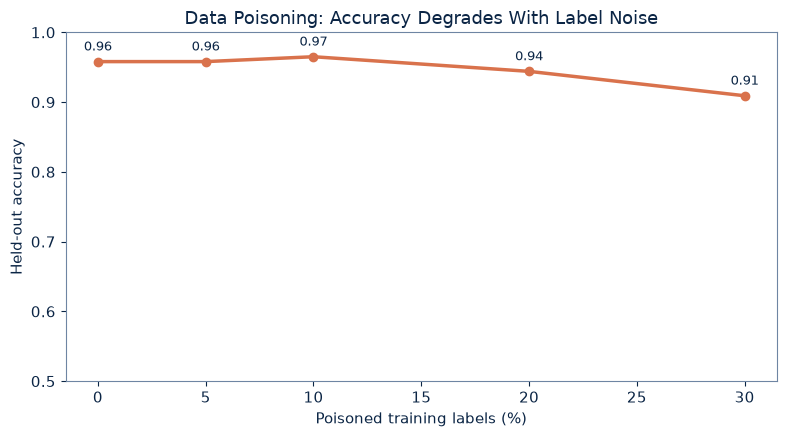


Even a modest amount of label noise meaningfully erodes accuracy on clean, held-out data.
Defenses: data validation pipelines, anomaly detection on incoming data, provenance tracking.


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # create an empty chart canvas
ax.plot([r * 100 for r in poison_rates], poisoned_accuracies, marker="o", color=ALERT, linewidth=2.5)  # draw a line: x = noise as a percentage, y = accuracy; "o" marks each data point
ax.set_xlabel("Poisoned training labels (%)")  # x-axis label
ax.set_ylabel("Held-out accuracy")  # y-axis label
ax.set_title("Data Poisoning: Accuracy Degrades With Label Noise")  # chart title
ax.set_ylim(0.5, 1.0)  # fix the y-axis between 0.5 (coin flip) and 1.0 (perfect) so the drop is easy to see
for r, a in zip(poison_rates, poisoned_accuracies):  # loop over each (noise level, accuracy) pair together
    ax.annotate(f"{a:.2f}", (r * 100, a), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)  # write the accuracy value just above each point
plt.tight_layout()  # tidy spacing so nothing is cut off
plt.show()  # draw the chart

print()  # blank line for readability
print("Even a modest amount of label noise meaningfully erodes accuracy on clean, held-out data.")  # takeaway line 1
print("Defenses: data validation pipelines, anomaly detection on incoming data, provenance tracking.")  # list of defences

**How to read the result**
- **X-axis:** what percentage of training labels were corrupted. **Y-axis:** accuracy on clean test data.
- The line is **flat or wobbly at first, then falls** as noise grows. That shape means "light noise is absorbed, heavy noise breaks the model".
- The model was never "hacked" in a technical sense. It simply learned from lies, which is why this threat is easy to miss.

**🛡️ Defences, in plain words:**
- **Data validation pipelines:** automatic checks on incoming data (valid ranges, no impossible values).
- **Anomaly detection on incoming data:** flag suspicious batches before they reach training.
- **Provenance tracking:** record *where every piece of data came from* and who touched it, so you can trace and remove bad sources.

---
## 1.4 — Input threats: a simple out-of-distribution (OOD) detector

### 🎯 The idea
A model only knows what it was trained on. If someone sends it an input that looks **nothing like its training data** (an out-of-distribution, or OOD, input), its answer is basically a guess, but it will still reply with confidence.

> 🐶 **Analogy:** A dog-breed classifier is shown a photo of a toaster. It will still say "Labrador, 82 %!" because it has no option to say "that is not a dog."

So we put a **security guard at the door**: a quick statistical check that asks *"does this input look like the data we trained on?"* before the model sees it.

### The method in plain English (Mahalanobis distance)
- Find the **average patient** in the training data (the centre of the "normal" cloud).
- Measure how **far** a new input sits from that centre. We use *Mahalanobis distance*, which is a smarter ruler than plain distance because it accounts for how features move together (for example, bigger tumours tend to have larger radius **and** area). An input that breaks those usual relationships scores high.
- Set a threshold from the training data itself: the **99th percentile**, meaning "99 % of normal training inputs score below this". Anything above it gets flagged.

### Step 1: Build and test the detector

**What we will do**
1. Learn the "normal" profile: the average and the feature-relationship table (covariance) of the training data.
2. Write a function that gives every input a distance score.
3. Set the alert threshold at the 99th percentile of training scores.
4. **Test A (should NOT alarm):** real held-out patients. Measure the false-alarm rate.
5. **Test B (SHOULD alarm):** 200 synthetic weird inputs, with several features pushed way outside the normal range. Measure the detection rate.

**The code**

In [10]:
# Fit a simple Gaussian model (mean + covariance) on the training feature distribution
train_mean = X_train.mean().values  # the "average patient": the mean of each of the 30 features
train_cov = np.cov(X_train.values, rowvar=False)  # covariance matrix: how every feature moves together with every other (rowvar=False = columns are features)
train_cov_inv = np.linalg.pinv(train_cov + np.eye(train_cov.shape[0]) * 1e-6)  # invert the matrix (needed for the distance maths); the tiny 1e-6 added to the diagonal avoids numerical errors

def mahalanobis_score(X_query):  # function: gives each row a "how unusual am I?" score (higher = stranger)
    diffs = X_query.values - train_mean  # for each row, how far each feature is from the average patient
    return np.einsum("ij,jk,ik->i", diffs, train_cov_inv, diffs)  # compact matrix maths that computes the squared Mahalanobis distance for every row at once

# Establish a detection threshold from the training data itself (e.g. 99th percentile)
train_scores = mahalanobis_score(X_train)  # score every training row to learn what "normal" scores look like
ood_threshold = np.percentile(train_scores, 99)  # the score that 99% of normal training rows fall below; our alarm line

# In-distribution check: real held-out test data
test_scores = mahalanobis_score(X_test)  # score the real, unseen test patients
false_positive_rate_ood = (test_scores > ood_threshold).mean()  # share of REAL patients wrongly flagged as strange (false alarms)

# Out-of-distribution check: synthetic inputs with an unrealistic combination of feature values
rng2 = np.random.default_rng(11)  # a separate random generator (seed 11) for creating the weird inputs
ood_samples = pd.DataFrame(  # build a table of 200 deliberately unrealistic inputs
    {col: rng2.uniform(X[col].min(), X[col].max(), 200) for col in feature_names}  # for each feature, pick values uniformly at random between its min and max, which ignores real-world feature relationships
)
# Push a few features further outside the training range to simulate a more extreme OOD case
for col in feature_names[:5]:  # loop over the first 5 features
    ood_samples[col] *= 1.8  # multiply them by 1.8 so they go well beyond anything seen in training
ood_scores = mahalanobis_score(ood_samples)  # score the weird inputs
detection_rate_ood = (ood_scores > ood_threshold).mean()  # share of weird inputs correctly flagged (higher is better)

print(f"OOD threshold (99th percentile of training scores): {ood_threshold:.1f}")  # print the alarm line
print(f"False positive rate on real held-out data (flagged as OOD): {false_positive_rate_ood:.1%}")  # print the false-alarm rate (lower is better)
print(f"Detection rate on synthetic OOD samples:                    {detection_rate_ood:.1%}")  # print the detection rate (higher is better)

OOD threshold (99th percentile of training scores): 152.3
False positive rate on real held-out data (flagged as OOD): 1.4%
Detection rate on synthetic OOD samples:                    100.0%


**How to read the result**
| Number | What you want | Why |
|---|---|---|
| **False positive rate** (real data flagged) | **Low** | Real patients should not be blocked |
| **Detection rate** (weird data flagged) | **High** | Strange inputs should be caught |

A good detector has *both*: few false alarms and many catches. The threshold is a dial: lower it and you catch more weird inputs but also annoy more real users.

### Step 2: See it in a chart

**The code**

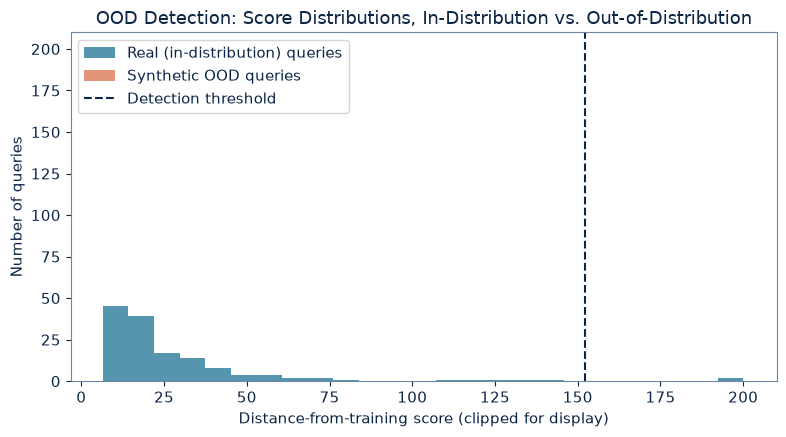


A statistical distance check like this can sit in front of the model as a cheap first
line of defense — flagging or rejecting inputs before they reach a model that was never
validated on data like that.


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # create an empty chart canvas
ax.hist(np.clip(test_scores, 0, 200), bins=25, alpha=0.75, color=TEAL, label="Real (in-distribution) queries")  # histogram of real-data scores; np.clip caps values at 200 so extreme ones do not stretch the chart
ax.hist(np.clip(ood_scores, 0, 200), bins=25, alpha=0.75, color=ALERT, label="Synthetic OOD queries")  # histogram of weird-input scores, also capped at 200 for display
ax.axvline(min(ood_threshold, 200), color=NAVY, linestyle="--", linewidth=1.5, label="Detection threshold")  # dashed vertical line = the alarm threshold (capped so it stays visible)
ax.set_xlabel("Distance-from-training score (clipped for display)")  # x-axis label
ax.set_ylabel("Number of queries")  # y-axis label
ax.set_title("OOD Detection: Score Distributions, In-Distribution vs. Out-of-Distribution")  # chart title
ax.legend()  # show the colour key
plt.tight_layout()  # tidy spacing
plt.show()  # draw the chart

print()  # blank line for readability
print("A statistical distance check like this can sit in front of the model as a cheap first")  # takeaway line 1
print("line of defense — flagging or rejecting inputs before they reach a model that was never")  # takeaway line 2
print("validated on data like that.")  # takeaway line 3

**How to read the result**
- **Teal bars** (real queries) should sit mostly **left** of the dashed line: they look normal.
- **Orange bars** (weird queries) should sit mostly **right** of the dashed line: they look strange.
- **Little overlap between the two colours = a good detector.** The more they overlap, the harder it is to separate normal from abnormal.
- The scores are clipped at 200 for display only. The real values for weird inputs can be much larger.

**Real-world uses:** reject or flag the request, route it to a human reviewer, or log it for investigation.

---
## 1.5 — Infrastructure & access threats: a query-rate anomaly detector

### 🎯 The idea
The extraction attack in Section 1.1 sent **1,500 queries**. Normal users send only a few per minute. That huge spike is a **loud alarm bell**, if anyone is listening.

> 🏦 **Analogy:** A bank notices that one card made 300 purchases in 5 minutes when the owner usually makes 4 a day. It does not need to understand the *intent*. The pattern alone triggers an alert.

### The method in plain English
- Measure what **normal traffic** looks like: an average and how much it normally wobbles (standard deviation, "std").
- Set the alarm at **mean + 3 × std**. Statistically, normal traffic almost never goes above this line.
- Any minute above the line is **flagged**.

### Step 1: Simulate and detect

**What we will do**
1. Simulate 60 minutes of **normal** traffic (around 4 queries per minute).
2. Make an **attack** copy: the same traffic, but minutes 40–44 each receive an extra 300 queries (1,500 ÷ 5 = 300 per minute).
3. Compute the threshold from the **normal** traffic only.
4. Flag every minute in the attack traffic that exceeds the threshold.

**The code**

In [12]:
# Simulate two traffic patterns over a 60-minute window, in one-minute buckets
minutes = np.arange(60)  # array [0, 1, 2, ... 59]: one entry for each minute of the hour

# Normal usage: a handful of queries per minute, occasionally more, but no extreme bursts
rng3 = np.random.default_rng(3)  # a random generator (seed 3) for repeatable fake traffic
normal_traffic = rng3.poisson(lam=4, size=60)  # 60 random counts averaging 4 queries/minute (Poisson = the standard model for "events per time window")

# Attack traffic: normal usage for the first 40 minutes, then the 1,500-query burst
# arrives compressed into a 5-minute window starting at minute 40
attack_traffic = normal_traffic.copy()  # start from a copy of normal traffic (so normal_traffic stays untouched)
attack_traffic[40:45] += N_QUERIES // 5  # add 300 extra queries to each of minutes 40, 41, 42, 43, 44 (// is whole-number division)

# A simple anomaly threshold: mean + 3 standard deviations of *normal* traffic
baseline_mean = normal_traffic.mean()  # the average queries per minute under normal use
baseline_std = normal_traffic.std()  # how much normal traffic typically varies minute to minute
anomaly_threshold = baseline_mean + 3 * baseline_std  # the alarm line: far above anything normal

flagged_minutes = minutes[attack_traffic > anomaly_threshold]  # keep only the minutes whose traffic exceeds the alarm line

print(f"Normal traffic: ~{baseline_mean:.1f} queries/minute (std {baseline_std:.1f})")  # show the normal average and its variation
print(f"Anomaly threshold (mean + 3 std): {anomaly_threshold:.1f} queries/minute")  # show the alarm line
print(f"Minutes flagged as anomalous: {flagged_minutes.tolist()}")  # list the minutes where the alarm fired (.tolist() converts to plain Python numbers for clean display)

Normal traffic: ~4.3 queries/minute (std 1.9)
Anomaly threshold (mean + 3 std): 9.9 queries/minute
Minutes flagged as anomalous: [23, 40, 41, 42, 43, 44]


**How to read the result**
- The **threshold** is a small number (about **9.9** queries/minute in our run), far below the attack's ~300 per minute.
- The **flagged minutes** include the whole attack window (**40 to 44**). You will probably also see **one extra minute (23)** flagged. That is a **false alarm**: a normal minute where random traffic happened to spike above the line.
- 🎓 **Teaching moment:** no threshold is perfect. A tighter line (mean + 3 std) catches attacks fast but occasionally cries wolf. Real systems often require *several minutes in a row* above the line before raising an alert.

### Step 2: Chart the traffic

**The code**

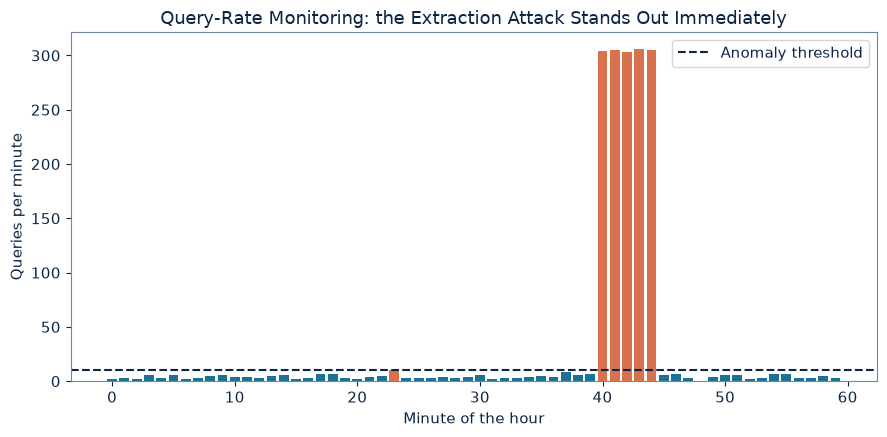


This is the same extraction attack from section 1.1, viewed from the infrastructure side.
Rate limiting and anomaly alerting would have caught it within minutes, not after the fact.


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))  # create an empty chart canvas (slightly wider for 60 bars)
ax.bar(minutes, attack_traffic, color=[ALERT if m in flagged_minutes else TEAL for m in minutes])  # one bar per minute; orange if flagged as anomalous, teal if normal
ax.axhline(anomaly_threshold, color=NAVY, linestyle="--", linewidth=1.5, label="Anomaly threshold")  # dashed horizontal line = the alarm threshold
ax.set_xlabel("Minute of the hour")  # x-axis label
ax.set_ylabel("Queries per minute")  # y-axis label
ax.set_title("Query-Rate Monitoring: the Extraction Attack Stands Out Immediately")  # chart title
ax.legend()  # show the colour key for the threshold line
plt.tight_layout()  # tidy spacing
plt.show()  # draw the chart

print()  # blank line for readability
print("This is the same extraction attack from section 1.1, viewed from the infrastructure side.")  # link back to Section 1.1
print("Rate limiting and anomaly alerting would have caught it within minutes, not after the fact.")  # main takeaway

**How to read the result**
- **Short teal bars** = normal usage. **Tall orange bars** = the attack (minutes 40–44), towering over the dashed alarm line. One small orange bar elsewhere is the false alarm described above.
- This detector knows nothing about *machine learning*. It simply notices unusual traffic, which is why basic infrastructure monitoring is such a powerful and cheap defence.

**🛡️ Defences, in plain words:**
- **Rate limiting:** cap how many queries one user or key can send per minute or day.
- **Alerting:** notify the security team automatically when traffic breaks the pattern.
- **Authentication and access control:** know *who* is calling your API and revoke keys on abuse.

---
## Block 1 recap: what did we learn?

| Section | Threat | What we saw | Core defence |
|---|---|---|---|
| **1.1** | Model extraction | 1,500 queries were enough to build a near-identical copy | Rate limiting, output perturbation, monitoring |
| **1.2** | Membership inference | The model is more confident on training data, which leaks who was in it | Differential privacy, regularization, confidence rounding |
| **1.3** | Data poisoning | More corrupted labels → lower accuracy on clean data | Data validation, anomaly detection, provenance |
| **1.4** | Out-of-distribution inputs | A distance check flags inputs unlike the training data | Input validation / OOD gate before the model |
| **1.5** | Infrastructure abuse | The attack burst stands out in simple traffic stats | Rate limits, alerting, authentication |

### Three big ideas to remember
1. **A model is an attack surface.** Accuracy alone does not mean "safe".
2. **Defences are layered.** No single check stops everything, but cheap checks (rate limits, input validation) stop a lot.
3. **These are teaching-scale demos.** Real systems need *continuous* monitoring, not a one-off notebook run.

➡️ **Next:** Block 2 shows how to protect the *data* itself through PII anonymisation.

---
## Block 2 — Data Privacy: PII Anonymisation

**Dataset:** Adult Income (UCI Census data, about 32,500 records). It has realistic quasi-identifiers (age, occupation, native country, education), which makes it a natural fit for anonymisation trade-offs.

### 🎯 The idea
Companies often release or share datasets after "removing the names". Surprisingly, **that is not enough**. A person can often still be picked out from a combination of ordinary-looking details.

> 🔎 **Analogy:** You do not need someone's name to find them if you know "a 39-year-old man, who works for the state government, holds a bachelor's degree, born in the USA." In a small enough crowd, that description points to exactly one person.

### Glossary for this block
| Term | Plain-English meaning |
|---|---|
| **PII** (Personally Identifiable Information) | Any data that can point to a specific person |
| **Direct identifier** | Identifies someone on its own (name, passport number, phone number) |
| **Quasi-identifier** | Harmless alone, but **identifying when combined** with others (age + job + country) |
| **Re-identification** | Working out who a "anonymous" record belongs to |
| **Group size / k-anonymity** | A record is hidden in a crowd of *k* identical-looking records. **k = 1** means you are unique; larger *k* is safer |
| **Generalisation** | Making details less precise (exact age 39 → age band "35-44") so more people look alike |

### What we will do in this block
1. Load the data and identify the quasi-identifiers
2. Measure re-identification risk from those columns alone
3. Apply generalisation (a k-anonymity style technique)
4. Compare risk **and** model usefulness before vs. after

> ℹ️ Other privacy techniques such as *masking* (hiding part of a value, e.g. `****-1234`) exist too, but this demo focuses on generalisation.

### Load the dataset

**What we will do**
1. Import the `shap` library, which happens to ship the Adult Income dataset.
2. Load it with readable category names (`display=True`, so you see "Private" instead of a number code).
3. Tidy the row numbering and name the target column.

**The code**

In [14]:
import shap  # the SHAP library; here we only use it because it bundles the Adult Income dataset

X_adult, y_adult = shap.datasets.adult(display=True)  # load the data: X = person details (features), y = income label; display=True gives readable text categories
X_adult = X_adult.reset_index(drop=True)  # restart the row numbers at 0, 1, 2, ... for a clean table
y_adult = pd.Series(y_adult, name="income_over_50k").reset_index(drop=True)  # wrap the labels in a named pandas Series (True = earns over $50K) with clean row numbers

print(f"Records: {X_adult.shape[0]}, Columns: {X_adult.shape[1]}")  # shape[0] = number of rows (people), shape[1] = number of columns
X_adult.head()  # show the first 5 rows so you can see what the data looks like

Records: 32561, Columns: 12


,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,State-gov,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States
1,50.0,Self-emp-not-inc,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States
2,38.0,Private,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States
3,53.0,Private,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States
4,28.0,Private,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba


**How to read the result**
- You should see **32,561 records and 12 columns**. Each row is one person described by age, workclass, education, marital status, occupation, race, sex, capital gain/loss, hours worked per week and country.
- Notice there is **no name, address or ID number**. This is the typical "anonymised" release. The next section shows why that is not the same as "safe".

---
## 2.1 — Classifying identifiers

### 🎯 The idea
This dataset has no direct identifiers (no names or SSNs). The real risk sits in the **quasi-identifiers**: fields that are not identifying alone, but can be **combined** to re-identify someone. An attacker with outside information (a voter list, a social-media profile, a neighbour's knowledge) can match those combinations to real people.

### Step 1: Choose the quasi-identifiers

**What we will do**
1. Pick six columns an outsider could plausibly know about someone: Age, Workclass, Education-Num, Occupation, Country, Sex.
2. Count how many different values each column has. More distinct values means more detail, and more detail means easier identification.

**The code**

In [15]:
quasi_identifiers = ["Age", "Workclass", "Education-Num", "Occupation", "Country", "Sex"]  # the columns we treat as "combinable clues" about a person

print("Quasi-identifiers selected for this demo:")  # heading line for the list below
for col in quasi_identifiers:  # go through each chosen column one at a time
    print(f"  - {col}: {X_adult[col].nunique()} unique values")  # nunique() counts how many different values the column contains

Quasi-identifiers selected for this demo:
  - Age: 73 unique values
  - Workclass: 9 unique values
  - Education-Num: 16 unique values
  - Occupation: 15 unique values
  - Country: 42 unique values
  - Sex: 2 unique values


**How to read the result**
In our run: Age has 73 distinct values, Workclass 9, Education-Num 16, Occupation 15, Country 42, Sex 2.

Multiply them together (73 × 9 × 16 × 15 × 42 × 2) and you get roughly **13 million possible combinations**, but the dataset holds only about **32,000 people**. With that many possible "boxes" and so few people, most people end up alone in their own box. That is exactly what we measure next.

### Step 2: Measure re-identification risk

**What we will do**
1. Group people who share exactly the same six quasi-identifier values.
2. Give every person a **group size** (how many people look identical to them).
3. Report: the share who are **unique** (group size 1), the share in a **risky small group** (5 or fewer), and the smallest group size overall (**k**).

**The code**

In [16]:
def group_size_stats(df, cols):  # function: for every row, find how many rows share its quasi-identifier values
    group_sizes = df.groupby(cols, observed=True).size()  # group identical combinations together and count each group's members
    record_group_sizes = df.merge(  # attach each group's size back onto every individual row
        group_sizes.rename("group_size"), left_on=cols, right_index=True  # match rows to their group by the quasi-identifier columns
    )["group_size"]  # keep only the group-size column
    return record_group_sizes  # one number per person: how many people look just like them

raw_group_sizes = group_size_stats(X_adult, quasi_identifiers)  # run it on the raw (un-anonymised) data

pct_unique = (raw_group_sizes == 1).mean()  # share of people who are alone in their group (uniquely identifiable)
pct_risky = (raw_group_sizes <= 5).mean()  # share of people hiding in a group of 5 or fewer (high risk)
min_group = raw_group_sizes.min()  # smallest group anywhere in the data: this is the dataset's k

print(f"Records that are UNIQUELY identifiable by these quasi-identifiers: {pct_unique:.1%}")  # report the unique share
print(f"Records in a group of 5 or fewer (high re-identification risk):    {pct_risky:.1%}")  # report the risky share
print(f"Smallest group size in the raw data (k = {min_group}):             this is the dataset's k-anonymity level")  # report k

Records that are UNIQUELY identifiable by these quasi-identifiers: 29.3%
Records in a group of 5 or fewer (high re-identification risk):    59.1%
Smallest group size in the raw data (k = 1):             this is the dataset's k-anonymity level


**How to read the result**
| Number | In our run | Meaning |
|---|---|---|
| **Uniquely identifiable** | about **29 %** | Nearly 3 in 10 people can be singled out using only six "harmless" columns |
| **In a group of 5 or fewer** | about **59 %** | Well over half the people have almost no crowd to hide in |
| **k (smallest group)** | **1** | The data is only 1-anonymous, meaning it offers **no real anonymity guarantee** |

**Key takeaway:** removing names did not make this dataset anonymous. Combinations of ordinary details can act like a fingerprint.

---
## 2.2 — Applying anonymisation

### 🎯 The idea
To hide people in a crowd, we make the details **less precise** so more people look alike. This is called **generalisation**. We apply it to the riskiest quasi-identifiers:
- **Age** → 10-year bands instead of exact age
- **Country** → collapsed to "United-States" vs. "Other" (rare countries are the most re-identifying)
- **Education-Num** → grouped into broad bands instead of exact years

### Step 1: Generalise the data

**What we will do**
1. Write a function `anonymize()` that works on a *copy* of the data (the original stays untouched).
2. Turn exact ages into six age bands.
3. Keep the most common country and rename every other country to "Other".
4. Turn exact education years into four broad education levels.

**The code**

In [17]:
def anonymize(df):  # function: returns a less-precise, safer copy of the data
    out = df.copy()  # work on a copy so the original dataset is never changed
    out["Age"] = pd.cut(  # pd.cut sorts numbers into labelled ranges ("bins")
        out["Age"], bins=[0, 25, 35, 45, 55, 65, 120],  # range edges: 0-25, 25-35, 35-45, 45-55, 55-65, 65-120
        labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"]  # readable name for each range
    )
    top_country = out["Country"].value_counts().idxmax()  # find the most common country (the biggest crowd to hide in)
    out["Country"] = np.where(out["Country"] == top_country, top_country, "Other")  # keep the top country; replace every other country with "Other"
    out["Education-Num"] = pd.cut(  # group exact years of education into broad levels
        out["Education-Num"], bins=[0, 9, 12, 16, 20],  # range edges: up to 9, 10-12, 13-16, 17-20 years
        labels=["Basic", "Secondary", "Undergraduate", "Advanced"]  # readable name for each level
    )
    return out  # hand back the generalised data

X_anon = anonymize(X_adult)  # create the anonymised version of the dataset
X_anon[quasi_identifiers].head()  # show the first 5 rows of the quasi-identifier columns to see the change

,Age,Workclass,Education-Num,Occupation,Country,Sex
0,35-44,State-gov,Undergraduate,Adm-clerical,United-States,Male
1,45-54,Self-emp-not-inc,Undergraduate,Exec-managerial,United-States,Male
2,35-44,Private,Basic,Handlers-cleaners,United-States,Male
3,45-54,Private,Basic,Handlers-cleaners,United-States,Male
4,25-34,Private,Undergraduate,Prof-specialty,Other,Female


**How to read the result**
Compare with the raw table: exact ages (39, 50, 38) became bands (35-44, 45-54, 35-44), exact education years became levels (Basic, Undergraduate...), and country is now just "United-States" or "Other". Each person is now **less precise, but still described**.

### Step 2: Compare risk before vs. after

**What we will do**
1. Re-run the same group-size measurement on the anonymised data.
2. Put the raw and anonymised results side by side in one table.

**The code**

In [18]:
anon_group_sizes = group_size_stats(X_anon, quasi_identifiers)  # measure group sizes again, now on the generalised data

pct_unique_anon = (anon_group_sizes == 1).mean()  # share of people still unique after anonymisation
pct_risky_anon = (anon_group_sizes <= 5).mean()  # share still in a group of 5 or fewer
min_group_anon = anon_group_sizes.min()  # smallest group size after anonymisation

comparison = pd.DataFrame({  # build a small side-by-side comparison table
    "Raw data": [pct_unique, pct_risky, min_group],  # column 1: the "before" numbers
    "Anonymized data": [pct_unique_anon, pct_risky_anon, min_group_anon],  # column 2: the "after" numbers
}, index=["% uniquely identifiable", "% in group of <=5 (high risk)", "Smallest group size (k)"])  # row names

comparison  # display the table

,Raw data,Anonymized data
% uniquely identifiable,0.292620,0.021314
% in group of <=5 (high risk),0.591352,0.088357
Smallest group size (k),1.000000,1.000000


**How to read the result**
| Measure | Raw | Anonymised (our run) |
|---|---|---|
| Uniquely identifiable | about 29 % | about **2 %** |
| In a group of 5 or fewer | about 59 % | about **9 %** |
| Smallest group size (k) | 1 | **still 1** |

Risk **dropped dramatically**, but note the honest detail: **k is still 1**, so a few hundred people (about 2 %) remain unique. This is *reduced risk*, not *perfect anonymity*. Reaching a guaranteed k (for example k ≥ 5) would need extra steps, such as grouping further or removing the leftover rare records (called *suppression*).

### Step 3: Chart the risk

**What we will do**
1. Draw two pairs of bars: "uniquely identifiable" and "high risk (group ≤ 5)".
2. Orange = raw data, teal = anonymised data, with the percentage on top of each bar.

**The code**

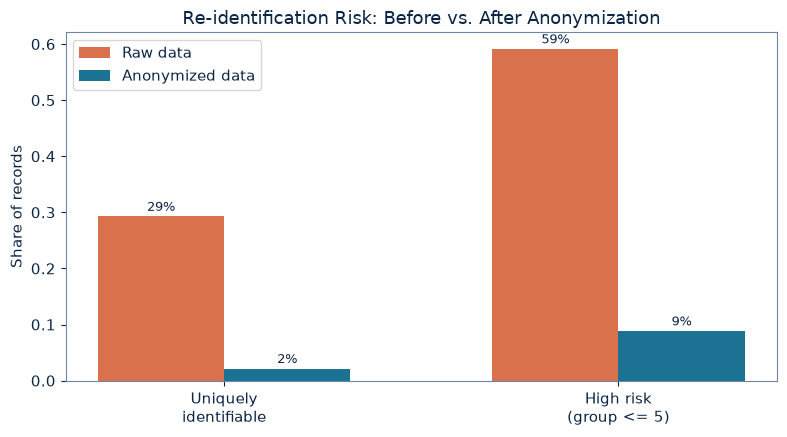

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # create an empty chart canvas
labels = ["Uniquely\nidentifiable", "High risk\n(group <= 5)"]  # the names under each pair of bars (\n starts a new line)
raw_vals = [pct_unique, pct_risky]  # heights of the "raw data" bars
anon_vals = [pct_unique_anon, pct_risky_anon]  # heights of the "anonymised data" bars

x = np.arange(len(labels))  # x-positions of the bar groups: 0 and 1
width = 0.32  # how wide each bar is
ax.bar(x - width/2, raw_vals, width, label="Raw data", color=ALERT)  # draw the raw-data bars, shifted slightly left
ax.bar(x + width/2, anon_vals, width, label="Anonymized data", color=TEAL)  # draw the anonymised bars, shifted slightly right
ax.set_xticks(x)  # place the x tick marks under each bar group
ax.set_xticklabels(labels)  # write the label names on those ticks
ax.set_ylabel("Share of records")  # y-axis label
ax.set_title("Re-identification Risk: Before vs. After Anonymization")  # chart title
ax.legend()  # show the colour key
for i, (r, a) in enumerate(zip(raw_vals, anon_vals)):  # loop over each pair of bars, with i = pair number
    ax.text(i - width/2, r + 0.01, f"{r:.0%}", ha="center", fontsize=9)  # write the raw percentage just above its bar
    ax.text(i + width/2, a + 0.01, f"{a:.0%}", ha="center", fontsize=9)  # write the anonymised percentage just above its bar
plt.tight_layout()  # tidy spacing
plt.show()  # draw the chart

**How to read the result**
The orange bars (raw) tower over the teal bars (anonymised) in both groups. A big visual gap means generalisation was **effective**.

**🛡️ Defences, in plain words**
- **Generalise** precise details into bands or broader categories.
- **Suppress** (remove) the rare records that still stand out.
- **Check the numbers**: measure group sizes *before* you release data, not after.

---
## 2.3 — The trade-off: does anonymisation cost us model utility?

### 🎯 The idea
Privacy is never free. Less precise data means a model has **less to learn from**. The practical question is: *how much usefulness do we lose in exchange for the privacy we gain?*

### Step 1: Train on raw vs. anonymised data

**What we will do**
1. Write a helper that converts text categories into numbers, splits the data, trains a **Gradient Boosting** model (a strong general-purpose model that learns from its own mistakes step by step) and returns its test accuracy.
2. Run it twice: once with the **raw** quasi-identifiers, once with the **anonymised** ones.
3. Subtract the two accuracies to see the utility cost.

**The code**

In [20]:
from sklearn.preprocessing import OrdinalEncoder  # converts text categories into numbers the model can use
from sklearn.ensemble import GradientBoostingClassifier  # the model type: builds many small trees, each correcting the last
from sklearn.model_selection import train_test_split  # splits data into training and test parts
from sklearn.metrics import accuracy_score  # share of correct predictions

def encode_and_score(df, cols, target, label):  # function: train a model on the chosen columns and report its test accuracy
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)  # text-to-number converter; unseen categories get the value -1 instead of crashing
    X_enc = enc.fit_transform(df[cols].astype(str))  # turn the chosen columns into text, then into numbers
    X_tr, X_te, y_tr, y_te = train_test_split(X_enc, target, test_size=0.25, random_state=42, stratify=target)  # 75% train / 25% test; same split every run; keep the income mix equal in both
    clf = GradientBoostingClassifier(random_state=42)  # create the model (fixed seed for repeatable results)
    clf.fit(X_tr, y_tr)  # TRAIN the model on the training part
    acc = accuracy_score(y_te, clf.predict(X_te))  # test it on the hidden part and compute accuracy
    print(f"{label}: accuracy using only quasi-identifiers = {acc:.3f}")  # print the accuracy with its label
    return acc  # return the accuracy so we can compare the two runs

acc_raw = encode_and_score(X_adult, quasi_identifiers, y_adult, "Raw quasi-identifiers")  # run on the precise, un-anonymised columns
acc_anon = encode_and_score(X_anon, quasi_identifiers, y_adult, "Anonymized quasi-identifiers")  # run on the generalised columns

print()  # blank line for readability
print(f"Utility cost of anonymization: {acc_raw - acc_anon:.3f} accuracy points")  # difference: how much accuracy we gave up
print("A small utility cost for a large drop in re-identification risk is usually a good trade.")  # takeaway

Raw quasi-identifiers: accuracy using only quasi-identifiers = 0.811
Anonymized quasi-identifiers: accuracy using only quasi-identifiers = 0.809

Utility cost of anonymization: 0.002 accuracy points
A small utility cost for a large drop in re-identification risk is usually a good trade.


**How to read the result**
- In our run, accuracy is about **0.811 on raw data** and **0.809 on anonymised data**, a cost of only about **0.002** (two tenths of a percentage point).
- For context, simply guessing "earns under $50K" for everyone would be right about **76 %** of the time, so both models do learn something useful from these six columns.
- **Key takeaway:** we cut re-identification risk massively and lost almost no predictive power. That is the ideal privacy trade.

⚠️ **Fair caveat:** this checks usefulness only for *one* task using *only* the six quasi-identifier columns. Other tasks may be more sensitive to the lost detail, so always re-test on your real use case.

### Block 2 recap
| Idea | What we saw |
|---|---|
| Removing names is not enough | About 29 % of people were unique from six ordinary columns |
| Generalisation works | Unique share fell to about 2 %, high-risk share to about 9 % |
| It is not perfect | k is still 1, so extra steps (suppression) are needed for a guarantee |
| Privacy has a (small) price | Accuracy changed by only about 0.002 |

---
## Block 3 — Responsible AI: Fairness & Explainability

**Dataset:** NHANES-I Health Survey (about 14,000 records), a real health survey with age and sex attributes. It is well suited to pairing **fairness metrics** with a **SHAP explanation**.

*(Session plan note: German Credit Data was originally proposed for this block, but that dataset is hosted on UCI/OpenML, which this environment's network allowlist cannot reach. NHANES-I is bundled with the `shap` library and gives the same fairness + explainability workflow on real data.)*

### 🎯 The idea
A model can have an excellent overall accuracy and still treat groups of people very differently. Responsible AI asks two questions:
1. **Fairness:** *Does the model make errors equally across groups?*
2. **Explainability:** *Why did the model decide what it decided?*

> 🏫 **Analogy:** A school reports "92 % of students passed", which sounds great. But if you split the numbers by class and one class passes at 70 %, the average was hiding a problem. Fairness checking is that split. Explainability is asking the teacher *why* that class struggled.

### Glossary for this block
| Term | Plain-English meaning |
|---|---|
| **Sensitive feature** | A personal attribute we want to check fairness for (here: sex) |
| **Selection rate** | How often the model predicts the "positive" outcome (here: "elevated mortality risk") for a group |
| **False positive** | The model says "high risk" but the person was actually fine |
| **False positive rate (FPR)** | Share of truly-fine people wrongly flagged as high risk |
| **Demographic parity difference** | Gap between groups in how often each is flagged. 0 means equal flagging rates |
| **Equalized odds difference** | Gap between groups in error rates (true- and false-positive rates). 0 means equal error rates |
| **SHAP** | A method that shows how much each feature pushed a prediction up or down |
| **Local vs. global explanation** | Local = why *this one person* got this result. Global = what drives the model *overall* |

### What we will do in this block
1. Train a mortality-risk model on a real clinical feature set
2. Slice accuracy and false-positive rate by sex
3. Compute demographic parity and equalized odds gaps
4. Explain one individual's prediction (local) and the whole model (global) with SHAP

### Load the data and prepare the label

**What we will do**
1. Load the NHANES-I dataset (health measurements for thousands of people, plus follow-up survival information).
2. Turn the survival information into a simple yes/no label: **did the person die during the study window?** (1 = yes, 0 = no).
3. Keep eight easy-to-understand health features.
4. Fill any missing values with each column's median (the middle value), so the model gets no blanks.

**The code**

In [21]:
import shap  # the SHAP library (imported here too, so this block can run on its own)

X_nhanes_full, y_nhanes_raw = shap.datasets.nhanesi()  # load the health survey: X = many measurements, y = follow-up time (positive = death observed)

# y > 0 means death was observed during the study window; y < 0 means the record was censored
# (the person was still alive at last follow-up). We build a binary "elevated mortality risk" label.
label_nhanes = (y_nhanes_raw > 0).astype(int)  # convert to 1 (death observed) or 0 (still alive at last follow-up)

feature_cols = [  # the eight features the model is allowed to use
    "sex_isFemale", "age", "physical_activity", "systolic_blood_pressure",  # sex, age, activity level, blood pressure
    "cholesterol", "bmi", "hemoglobin", "white_blood_cells",  # cholesterol, body-mass index, blood measurements
]
X_nhanes = X_nhanes_full[feature_cols].copy()  # keep only those eight columns (as a safe copy)
X_nhanes = X_nhanes.fillna(X_nhanes.median(numeric_only=True))  # replace any missing numbers with that column's median

print(f"Records: {X_nhanes.shape[0]}")  # number of people
print(f"Positive rate (elevated mortality risk during study window): {label_nhanes.mean():.1%}")  # share of people labelled 1
X_nhanes.head()  # show the first 5 rows

Records: 14264
Positive rate (elevated mortality risk during study window): 33.0%


,sex_isFemale,age,physical_activity,systolic_blood_pressure,cholesterol,bmi,hemoglobin,white_blood_cells
20751,False,51,3,110.0,256.0,25.406803,16.0,10.1
20753,False,41,2,136.0,254.0,24.588331,14.1,6.3
20754,True,31,2,110.0,177.0,23.756502,12.0,7.8
20755,False,48,2,126.0,209.0,28.610011,12.7,5.1
20756,True,29,3,98.0,206.0,19.216489,12.3,5.2


**How to read the result**
- About **14,264 people** and **8 features**.
- The **positive rate is about 33 %**: roughly one in three people in the study died during follow-up. This matters later: it means the "positive" class is fairly common, not rare.
- Notice `sex_isFemale` is `True/False`, a simple yes/no column.

### Train the model

**What we will do**
1. Split into 75 % training and 25 % test data. We also keep each test row's original index number, so we can look up the person's sex later.
2. Train a **Gradient Boosting** classifier (many small trees, each fixing the previous trees' mistakes).
3. Report the overall test accuracy.

**The code**

In [22]:
from sklearn.model_selection import train_test_split  # splits data into training and test parts
from sklearn.ensemble import GradientBoostingClassifier  # the model type for this block
from sklearn.metrics import accuracy_score  # share of correct predictions

Xn_train, Xn_test, yn_train, yn_test, idx_train, idx_test = train_test_split(  # split features, labels AND row indexes together
    X_nhanes, label_nhanes, X_nhanes.index, test_size=0.25, random_state=42, stratify=label_nhanes  # 25% test; fixed seed; keep the 33% positive rate equal in both parts
)

health_model = GradientBoostingClassifier(random_state=42, n_estimators=150, max_depth=3)  # 150 small trees, each at most 3 questions deep
health_model.fit(Xn_train, yn_train)  # TRAIN the model on the training part

overall_acc = accuracy_score(yn_test, health_model.predict(Xn_test))  # accuracy on the hidden test part
print(f"Overall test accuracy: {overall_acc:.3f}")  # show the overall accuracy
print("Looks solid in aggregate — now let's check whether it's equally solid across groups.")  # lead-in to the fairness check

Overall test accuracy: 0.827
Looks solid in aggregate — now let's check whether it's equally solid across groups.


**How to read the result**
- Overall accuracy is about **0.83**, which looks solid.
- But remember the school analogy: a single average can hide differences between groups. The next section checks that.

---
## 3.1 — Slicing metrics by sex

### 🎯 The idea
Aggregate accuracy can hide very different error patterns for different groups. We use `fairlearn.metrics.MetricFrame` to slice **accuracy**, **false-positive rate** and **selection rate** by sex.

### Step 1: Build the metrics-by-group table

**What we will do**
1. Look up each test person's sex and rename `True/False` to "Female"/"Male" for readability.
2. Get the model's predictions for the test set.
3. Ask `MetricFrame` to calculate three metrics **separately for each sex**.

**The code**

In [23]:
from fairlearn.metrics import MetricFrame, false_positive_rate, selection_rate  # fairlearn = a toolkit for measuring fairness

sex_test = X_nhanes.loc[idx_test, "sex_isFemale"].map({True: "Female", False: "Male"})  # look up each test person's sex by row index; rename True/False to readable labels
predictions_test = health_model.predict(Xn_test)  # the model's 0/1 predictions for every test person

metric_frame = MetricFrame(  # the tool that calculates metrics separately for each group
    metrics={  # the metrics we want, each with a display name
        "accuracy": accuracy_score,  # how often predictions are correct
        "false_positive_rate": false_positive_rate,  # share of people who did NOT die but were flagged high-risk
        "selection_rate": selection_rate,  # share of people flagged high-risk at all
    },
    y_true=yn_test,  # the true outcomes
    y_pred=predictions_test,  # the model's predictions
    sensitive_features=sex_test,  # the attribute to split by (sex)
)

print("Metrics by sex:")  # heading line
metric_frame.by_group  # display the table: one row per group, one column per metric

Metrics by sex:


,accuracy,false_positive_rate,selection_rate
sex_isFemale,,,
Female,0.841418,0.081607,0.219683
Male,0.804501,0.168553,0.433896


**How to read the result**
In our run:
| Group | Accuracy | False positive rate | Selection rate |
|---|---|---|---|
| Female | about 84 % | about **8 %** | about 22 % |
| Male | about 80 % | about **17 %** | about 43 % |

- **Accuracy** differs a little (84 % vs. 80 %), which is easy to overlook.
- **False positive rate is about double for men.** Men who were fine were flagged as high-risk about twice as often as women who were fine.
- **Selection rate** shows men were flagged about twice as often overall.

⚠️ **Important nuance:** some of the difference in *selection* can be **real**, because in this data men genuinely died more often during follow-up. That is why we also look at **error rates** (next step) rather than relying on flagging rates alone.

### Step 2: Calculate the two summary gaps

**What we will do**
1. Compute the **demographic parity difference**: the gap in how often each group is flagged.
2. Compute the **equalized odds difference**: the largest gap in error rates between the groups.
3. Remember: **0 means perfectly equal.**

**The code**

In [24]:
from fairlearn.metrics import demographic_parity_difference, equalized_odds_difference  # two standard fairness gap measures

dp_gap = demographic_parity_difference(yn_test, predictions_test, sensitive_features=sex_test)  # gap in selection (flagging) rates between the groups
eo_gap = equalized_odds_difference(yn_test, predictions_test, sensitive_features=sex_test)  # largest gap in true-positive or false-positive rates between the groups

print(f"Demographic parity difference: {dp_gap:.3f}  (0 = identical positive-prediction rates across groups)")  # print the first gap
print(f"Equalized odds difference:     {eo_gap:.3f}  (0 = identical TPR and FPR across groups)")  # print the second gap

Demographic parity difference: 0.214  (0 = identical positive-prediction rates across groups)
Equalized odds difference:     0.151  (0 = identical TPR and FPR across groups)


**How to read the result**
| Metric | In our run | What it says |
|---|---|---|
| **Demographic parity difference** | about **0.21** | Men and women are flagged at rates about 21 percentage points apart |
| **Equalized odds difference** | about **0.15** | Error rates differ by up to about 15 percentage points between the groups |

Both are well above 0. A common rule-of-thumb target in many policies is a gap **below about 0.05**, though the right limit depends on context.

**Which gap matters more?** Demographic parity can look "unfair" even when real-world base rates differ. Equalized odds asks a more precise question: *"Among people with the same true outcome, is the model equally right or wrong for each group?"*

### Step 3: Chart the gaps

**What we will do**
1. Draw two bar charts side by side: accuracy by sex, and false-positive rate by sex.
2. Write the exact value on each bar.

**The code**

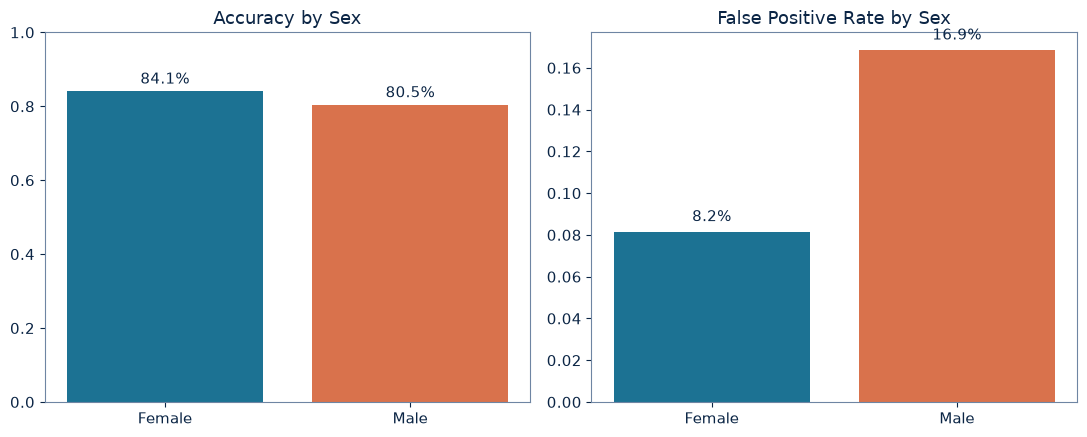

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))  # one canvas holding two charts side by side
by_group = metric_frame.by_group  # reuse the metrics-by-sex table from earlier

axes[0].bar(by_group.index, by_group["accuracy"], color=[TEAL, ALERT])  # left chart: one bar per sex showing accuracy
axes[0].set_title("Accuracy by Sex")  # left chart title
axes[0].set_ylim(0, 1)  # y-axis from 0 to 1 (0% to 100%)
for i, v in enumerate(by_group["accuracy"]):  # loop over each bar (i = position, v = value)
    axes[0].text(i, v + 0.02, f"{v:.1%}", ha="center")  # write the percentage just above the bar

axes[1].bar(by_group.index, by_group["false_positive_rate"], color=[TEAL, ALERT])  # right chart: one bar per sex showing false-positive rate
axes[1].set_title("False Positive Rate by Sex")  # right chart title
for i, v in enumerate(by_group["false_positive_rate"]):  # loop over each bar
    axes[1].text(i, v + 0.005, f"{v:.1%}", ha="center")  # write the percentage just above the bar

plt.tight_layout()  # tidy spacing
plt.show()  # draw the charts

**How to read the result**
- **Left chart (accuracy):** the two bars look fairly similar, which is why a single accuracy number can feel reassuring.
- **Right chart (false-positive rate):** the male bar is roughly **double** the female bar. This is the hidden problem. The model's mistakes are **not spread evenly**.

Fairness metrics tell us **whether** a gap exists. They do not tell us **why**. That is what the next section is for.

---
## 3.2 — Explaining predictions with SHAP: local and global

### 🎯 The idea
**Local** explanation: *why did the model decide this, for this one person?* **Global** explanation: *what drives the model's behaviour overall?* Both matter. Fairness metrics tell us *whether* a gap exists, and explanations help us understand *why*.

> 🧾 **Analogy:** SHAP works like an itemised receipt for a prediction. The final price (the model's output) is the total, and each feature is a line item that added to or subtracted from it.

### Step 1: Explain one person (local)

**What we will do**
1. Create a SHAP **explainer** designed for tree-based models.
2. Calculate SHAP values for every test record (how much each feature pushed that person's result).
3. Pick one person (test record number 3), show what the model predicted and what actually happened.
4. Draw a **waterfall chart** that breaks that one prediction into feature-by-feature pushes.

**The code**

Explaining prediction for test record #3
Predicted class: 0  |  Actual label: 0


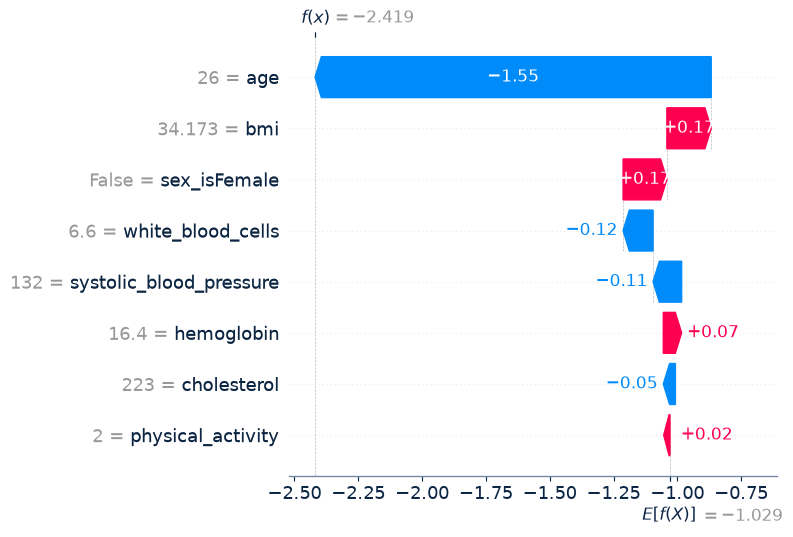

In [26]:
import shap as shap_lib  # import SHAP under a second name (same library; the name matches the notebook's original code)

explainer = shap_lib.TreeExplainer(health_model)  # build an explainer specialised for tree-based models like ours
shap_values = explainer(Xn_test)  # calculate every feature's contribution for every test person

# LOCAL: explain one individual test record
sample_idx = 3  # choose which test person to explain (the 4th one; counting starts at 0)
print(f"Explaining prediction for test record #{sample_idx}")  # say which person we are explaining
print(f"Predicted class: {predictions_test[sample_idx]}  |  Actual label: {yn_test[sample_idx]}")  # show the model's prediction and the real outcome

shap_lib.plots.waterfall(shap_values[sample_idx], show=False)  # draw the waterfall chart for that one person (show=False lets us tidy it first)
plt.tight_layout()  # tidy spacing
plt.show()  # display the chart

**How to read the waterfall chart** (follow it from bottom to top):
1. **`E[f(X)]` at the bottom** is the model's **starting point**: its average prediction across everyone. In our run it is about **−1.03**.
2. Each row above is a **feature**. A **red** bar pushes the risk **up**, a **blue** bar pushes it **down**. A longer bar means a stronger push. The grey number beside the feature name is that person's actual value (for example `age = 26`).
3. **`f(x)` at the top** is the final score after adding all pushes. In our run it is about **−2.42**, meaning a **low predicted risk**.

**What the example shows (our run):** this person is a **26-year-old man**. His **age** pulled the risk down by a large amount (about −1.55), which is the single biggest push. His BMI and sex nudged it up slightly, and the other features nudged it down slightly. The model predicted class 0 (low risk), and the actual label was also 0, so the prediction was correct.

📏 **A note on units:** these numbers are in **log-odds** (a stretched scale used inside models), not percentages. Just remember: **below 0 = leaning "low risk", above 0 = leaning "high risk"**, and bigger distance from 0 = stronger confidence. For reference, −2.42 corresponds to roughly an **8 % predicted risk**.

### Step 2: Explain the whole model (global)

**What we will do**
1. Take the SHAP values for **all** test people.
2. For each feature, average the size of its push (ignoring up or down direction).
3. Draw a bar chart ranking the features by overall importance.

**The code**

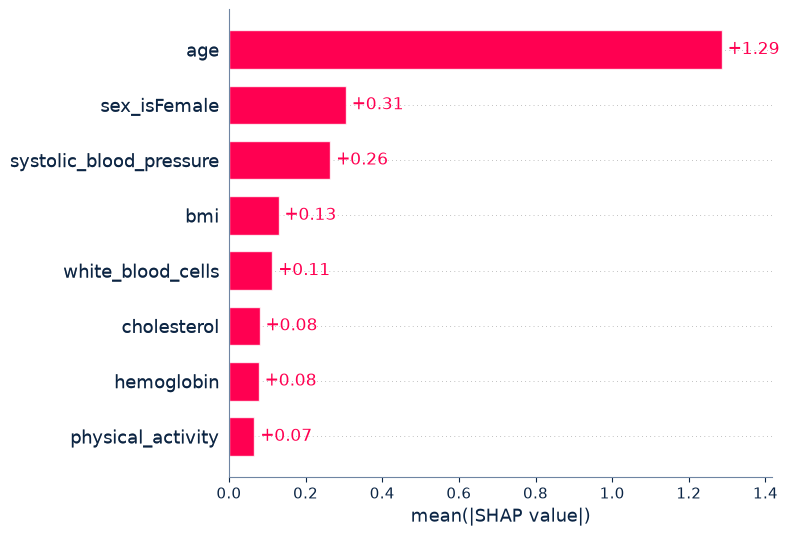

In [27]:
# GLOBAL: feature importance across all test records
shap_lib.plots.bar(shap_values, show=False)  # draw a bar chart of each feature's average absolute SHAP value (its overall influence)
plt.tight_layout()  # tidy spacing
plt.show()  # display the chart

**How to read the result**
Each bar is the **average size of that feature's push** on predictions. Longer bar = more influence. In our run:

| Rank | Feature | Average push |
|---|---|---|
| 1 | **age** | about 1.29 (by far the biggest) |
| 2 | **sex_isFemale** | about 0.31 |
| 3 | systolic blood pressure | about 0.26 |
| 4 to 8 | BMI, white blood cells, cholesterol, hemoglobin, physical activity | each about 0.07 to 0.13 |

**What this tells us:**
- **Age dominates**, which makes medical sense: mortality risk rises strongly with age.
- **Sex ranks second.** The model uses sex **directly** as an input, which links back to the fairness gap in 3.1. This is a good place to start asking *"should this feature be here, and what happens if we remove it?"*
- ⚠️ **Caution:** SHAP shows what the **model relies on**. It does not prove real-world cause and effect.

### Block 3 recap
| Question | Tool | What we found |
|---|---|---|
| Is it equally accurate for everyone? | `MetricFrame` | Accuracy gap is small (84 % vs. 80 %) |
| Is it equally *wrong* for everyone? | False positive rate, equalized odds | Men's false positive rate is about double; equalized odds gap is about 0.15 |
| Why did it decide this for one person? | SHAP waterfall | Age was the biggest push for the example person |
| What drives the model overall? | SHAP bar chart | Age first, then sex, then blood pressure |

---
## Block 4 — Case Study: Drift + Fairness Monitoring

**Dataset:** Diabetes (scikit-learn, 442 patients, 10 physiological features). We split the patients by a real feature (age) to simulate a genuine shift in the population over "time". This is the same structure as the case study in the deck, where the applicant population skewed older over six months.

### 🎯 The idea
A model is trained on yesterday's data but used on tomorrow's customers. If the population **changes** after launch (**drift**), the model quietly gets worse, and it may get worse **more for some groups than others**. The lesson: *monitor continuously, and check fairness again after drift.*

> 🍕 **Analogy:** A pizza shop perfects its menu for students, then an office opens next door. The same menu now disappoints the new, older customers, and not equally for everyone.

### Glossary for this block
| Term | Plain-English meaning |
|---|---|
| **Drift** | The incoming data changes compared with the data the model was trained on |
| **PSI** (Population Stability Index) | A score for how much a feature's distribution has shifted. Under 0.1 = stable, 0.1 to 0.2 = moderate, above 0.2 = significant |
| **Constrained retrain** | Re-training a model with a built-in rule, here "keep error rates similar across groups" |
| **Policy threshold** | A limit an organisation sets, such as "fairness gap must be below 5 %" |

### What we will do in this block
1. Train on an earlier ("launch") age slice, evaluate on a later ("month 6") age slice
2. Track the accuracy drop and a simple drift signal (PSI)
3. Compute a fairness-style gap (false-positive rate by sex) on the drifted data
4. Retrain with a fairness constraint and compare accuracy vs. fairness before/after

### Step 1: Create the two cohorts

**What we will do**
1. Load the diabetes dataset.
2. Turn the continuous disease-progression score into a yes/no label: **above the median = "high progression"**.
3. Split patients by the median age. The younger half becomes the **"launch" population**, and the older half becomes the **"month 6" population**.

**The code**

In [28]:
from sklearn.datasets import load_diabetes  # built-in example dataset: diabetes patient measurements

diabetes = load_diabetes(as_frame=True)  # load the dataset as pandas tables
X_diab = diabetes.data.copy()  # the patient measurements (features); copy so we never alter the original
y_diab_continuous = diabetes.target  # the disease-progression score (a continuous number)

# Binarize: "high disease progression" = above the median
y_diab = (y_diab_continuous > y_diab_continuous.median()).astype(int)  # 1 if above the median score, otherwise 0

# Use age to define two cohorts, simulating a population that skews older over time
age_median = X_diab["age"].median()  # the middle age value (the dataset stores age in standardised units)
cohort_launch = X_diab["age"] <= age_median   # True for the younger half: the "at launch" population
cohort_month6 = X_diab["age"] > age_median    # True for the older half: the "month 6" population, skewed older

print(f"Launch cohort size:  {cohort_launch.sum()}")  # count the True values: patients in the launch group
print(f"Month-6 cohort size:  {cohort_month6.sum()}")  # patients in the month-6 group

Launch cohort size:  227
Month-6 cohort size:  215


**How to read the result**
You should see about **227 launch patients** and **215 month-6 patients** (442 in total). The two groups differ systematically by age, which is how we simulate real-world drift.

---
## 4.1 — Detecting the drift

### Step 1: Measure the accuracy drop

**What we will do**
1. Select eight features and separate launch and month-6 patients.
2. Split the **launch** data into train (70 %) and test (30 %).
3. Train a **logistic regression** model (a simple, classic model that predicts a yes/no outcome) on launch training data only.
4. Test it twice: on held-out **launch** data (what it was built for) and on **month-6** data (the shifted population).

**The code**

In [29]:
from sklearn.model_selection import train_test_split  # splits data into training and test parts
from sklearn.linear_model import LogisticRegression  # a simple, classic yes/no prediction model
from sklearn.metrics import accuracy_score  # share of correct predictions

feature_cols_diab = ["bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]  # the eight measurement columns the model will use (bmi, blood pressure, six blood-serum measures)

X_launch, y_launch = X_diab.loc[cohort_launch, feature_cols_diab], y_diab.loc[cohort_launch]  # features and labels for launch-cohort patients
X_month6, y_month6 = X_diab.loc[cohort_month6, feature_cols_diab], y_diab.loc[cohort_month6]  # features and labels for month-6 patients

X_launch_train, X_launch_test, y_launch_train, y_launch_test = train_test_split(  # split ONLY the launch data into train and test parts
    X_launch, y_launch, test_size=0.3, random_state=42, stratify=y_launch  # 30% test; fixed seed; keep the label mix equal
)

drift_model = LogisticRegression(max_iter=1000)  # create the model (max_iter=1000 gives it enough tries to converge)
drift_model.fit(X_launch_train, y_launch_train)  # TRAIN it on launch training data only

acc_in_distribution = accuracy_score(y_launch_test, drift_model.predict(X_launch_test))  # accuracy on held-out LAUNCH patients (familiar population)
acc_month6 = accuracy_score(y_month6, drift_model.predict(X_month6))  # accuracy on MONTH-6 patients (shifted population)

print(f"Accuracy on held-out LAUNCH data (in-distribution): {acc_in_distribution:.3f}")  # accuracy on the familiar population
print(f"Accuracy on MONTH-6 data (shifted population):      {acc_month6:.3f}")  # accuracy on the new population
print(f"Accuracy drop from drift:                            {acc_in_distribution - acc_month6:.3f}")  # how much accuracy was lost

Accuracy on held-out LAUNCH data (in-distribution): 0.681
Accuracy on MONTH-6 data (shifted population):      0.553
Accuracy drop from drift:                            0.128


**How to read the result**
In our run: **about 0.68 on launch data** vs. **about 0.55 on month-6 data**, a drop of about **0.13**. An accuracy of 0.55 is only slightly better than a coin flip. Nothing in the model changed, only the **people** it sees.

⚠️ In real life you often **cannot** compute this accuracy straight away, because the true outcomes arrive late. That is why we also use a drift signal that needs **no labels**, which comes next.

### Step 2: Measure the shift with PSI

**What we will do**
1. Split a feature's launch values into 10 equal-sized buckets.
2. Count what share of launch patients and month-6 patients fall into each bucket.
3. Combine the differences into one number, the **PSI**. A bigger PSI means a bigger shift.
4. Label the result: **above 0.2** = significant shift, **0.1 to 0.2** = moderate, **below 0.1** = stable.

**The code**

In [30]:
def population_stability_index(expected, actual, bins=10):  # function: score how much a feature's distribution has shifted
    breakpoints = np.quantile(expected, np.linspace(0, 1, bins + 1))  # bucket edges that split the launch data into 10 equal-sized groups
    breakpoints[0], breakpoints[-1] = -np.inf, np.inf  # open the first and last bucket so no new value falls outside
    expected_pct = np.histogram(expected, bins=breakpoints)[0] / len(expected)  # share of launch patients in each bucket
    actual_pct = np.histogram(actual, bins=breakpoints)[0] / len(actual)  # share of month-6 patients in each bucket
    expected_pct = np.clip(expected_pct, 1e-4, None)  # avoid zeros (we divide and take logs below)
    actual_pct = np.clip(actual_pct, 1e-4, None)  # same protection for the month-6 shares
    return np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct))  # the PSI formula: bigger = more shift

for feat in ["bmi", "bp"]:  # check two features: body-mass index and blood pressure
    psi = population_stability_index(X_launch[feat].values, X_month6[feat].values)  # compute PSI between launch and month-6 values
    flag = "SIGNIFICANT SHIFT" if psi > 0.2 else ("moderate shift" if psi > 0.1 else "stable")  # translate the number into a label
    print(f"PSI for '{feat}': {psi:.3f}  -> {flag}")  # print the feature, its PSI and the label

PSI for 'bmi': 0.441  -> SIGNIFICANT SHIFT
PSI for 'bp': 0.554  -> SIGNIFICANT SHIFT


**How to read the result**
In our run, **BMI has a PSI of about 0.44** and **blood pressure about 0.55**. Both are far above the 0.2 line, so both are flagged **SIGNIFICANT SHIFT**.

This is the early-warning system: PSI can flag drift **before** you know the true outcomes. A typical real-world response is to trigger an investigation or retraining.

---
## 4.2 — The hidden cost: checking fairness on the drifted evaluation

### 🎯 The idea
Drift does not just lower accuracy overall. It can also **change who bears the errors**. After drift we must re-check fairness, not just accuracy.

> 🏷️ **Note on "Group A / Group B":** the diabetes dataset stores sex as two standardised numbers (one negative, one positive) and does not say which is male or female. So the code labels them **Group A** (negative value) and **Group B** (positive value) rather than guessing.

### Step 1: Slice the month-6 results by group

**What we will do**
1. Assign each month-6 patient to Group A or Group B.
2. Get the model's month-6 predictions.
3. Use `MetricFrame` to compute accuracy and false-positive rate for each group.

**The code**

In [31]:
from fairlearn.metrics import MetricFrame, false_positive_rate  # tools for slicing metrics by group

sex_month6 = X_diab.loc[cohort_month6, "sex"].map(lambda v: "Group A" if v < 0 else "Group B")  # label each month-6 patient: negative sex value = Group A, otherwise Group B
predictions_month6 = drift_model.predict(X_month6)  # the original (launch-trained) model's predictions on month-6 patients

fairness_before = MetricFrame(  # calculate metrics separately for each group
    metrics={"accuracy": accuracy_score, "false_positive_rate": false_positive_rate},  # the two metrics we want
    y_true=y_month6, y_pred=predictions_month6, sensitive_features=sex_month6,  # true outcomes, predictions, and the group labels
)

print("Fairness metrics on month-6 data, BEFORE any fix:")  # heading line
fairness_before.by_group  # display one row per group

Fairness metrics on month-6 data, BEFORE any fix:


,accuracy,false_positive_rate
sex,,
Group A,0.505155,0.000000
Group B,0.593220,0.019608


**How to read the result**
In our run, accuracy is about **0.51 for Group A** and **0.59 for Group B**. Both are poor, and they differ. The false-positive rates are tiny (0 % and about 2 %). This means the model **rarely raises a false alarm**, but it is probably missing many true cases instead. That kind of imbalance is exactly what the next measure captures.

### Step 2: Calculate the equalized odds gap

**What we will do**
1. Compute the equalized odds difference on the month-6 predictions (error-rate gap between the groups).
2. Keep this number as the **"before the fix"** reference.

**The code**

In [32]:
from fairlearn.metrics import equalized_odds_difference  # largest gap in error rates between groups

eo_gap_before = equalized_odds_difference(y_month6, predictions_month6, sensitive_features=sex_month6)  # compute the gap on the drifted data
print(f"Equalized odds gap BEFORE fix: {eo_gap_before:.3f}")  # print the "before" gap

Equalized odds gap BEFORE fix: 0.126


**How to read the result**
The gap is about **0.13**, well above the 5 % (0.05) policy line used later in this block. So after drift the model is both **less accurate** and **unevenly wrong** across the two groups.

---
## 4.3 — Retraining with a fairness constraint

### 🎯 The idea
Instead of retraining only for accuracy, we retrain with a **rule**: *keep the error rates similar across groups.* The `ExponentiatedGradient` method from fairlearn does this by repeatedly re-weighting the training examples until the constraint (`EqualizedOdds`) is met as closely as possible.

### Step 1: Retrain two ways and compare

**What we will do**
1. Split the month-6 patients in half: one half joins the retraining data, the other half is a **fresh holdout** for fair testing.
2. Combine the launch training data with the month-6 retraining half, so the new model sees both populations.
3. Train **model A (fairness-constrained)** and **model B (accuracy-only)** on the same combined data.
4. Compare both on the holdout: accuracy and equalized odds gap.

**The code**

In [33]:
from fairlearn.reductions import ExponentiatedGradient, EqualizedOdds  # fairness-constrained training tools

X_month6_retrain, X_month6_holdout, y_month6_retrain, y_month6_holdout, sex_retrain, sex_holdout = (  # split month-6 data (features, labels, groups) into two halves
    train_test_split(X_month6, y_month6, sex_month6, test_size=0.5, random_state=42, stratify=y_month6)  # 50/50 split; fixed seed; keep the label mix equal
)

X_retrain_combined = pd.concat([X_launch_train, X_month6_retrain])  # new training features: launch training data + month-6 retrain half
y_retrain_combined = pd.concat([y_launch_train, y_month6_retrain])  # matching labels for the combined data
sex_retrain_combined = pd.concat([  # matching group labels (Group A / Group B) for the combined data
    X_diab.loc[X_launch_train.index, "sex"].map(lambda v: "Group A" if v < 0 else "Group B"),  # group labels for the launch training patients
    sex_retrain,  # group labels for the month-6 retrain patients
])

fair_model = ExponentiatedGradient(  # model A: trains with a fairness rule built in
    estimator=LogisticRegression(max_iter=1000),  # the underlying model type being trained
    constraints=EqualizedOdds(),  # the rule: keep true- and false-positive rates similar across groups
)
fair_model.fit(X_retrain_combined, y_retrain_combined, sensitive_features=sex_retrain_combined)  # TRAIN model A (it needs the group labels to apply the rule)

predictions_fair = fair_model.predict(X_month6_holdout)  # model A's predictions on the fresh holdout
acc_after = accuracy_score(y_month6_holdout, predictions_fair)  # model A's accuracy
eo_gap_after = equalized_odds_difference(y_month6_holdout, predictions_fair, sensitive_features=sex_holdout)  # model A's fairness gap

accuracy_only_model = LogisticRegression(max_iter=1000)  # model B: a plain model with no fairness rule
accuracy_only_model.fit(X_retrain_combined, y_retrain_combined)  # TRAIN model B on the same combined data
predictions_acc_only = accuracy_only_model.predict(X_month6_holdout)  # model B's predictions on the same holdout
acc_accuracy_only = accuracy_score(y_month6_holdout, predictions_acc_only)  # model B's accuracy
eo_gap_accuracy_only = equalized_odds_difference(y_month6_holdout, predictions_acc_only, sensitive_features=sex_holdout)  # model B's fairness gap

print(f"{'Approach':<32}{'Accuracy':>12}{'Equalized Odds Gap':>22}")  # table header, with fixed column widths
print(f"{'Accuracy-only retrain':<32}{acc_accuracy_only:>12.3f}{eo_gap_accuracy_only:>22.3f}")  # row for model B
print(f"{'Fairness-constrained retrain':<32}{acc_after:>12.3f}{eo_gap_after:>22.3f}")  # row for model A

Approach                            Accuracy    Equalized Odds Gap
Accuracy-only retrain                  0.750                 0.280
Fairness-constrained retrain           0.667                 0.180


**How to read the result**
In our run:
| Approach | Accuracy | Equalized odds gap |
|---|---|---|
| Accuracy-only retrain | about **0.75** | about **0.28** |
| Fairness-constrained retrain | about **0.66 to 0.67** | about **0.15 to 0.18** |

- The fairness constraint **cuts the gap substantially** (0.28 → about 0.15 to 0.18).
- It **costs accuracy**: about 8 to 9 percentage points here. That is a real trade-off, not a free win.
- ⚠️ The constrained model's gap (about 0.15 to 0.18) is **still above the 0.05 policy line**. Fairness constraints reduce gaps. They do not always eliminate them.
- 🎲 **Your numbers may differ slightly.** `ExponentiatedGradient` combines several models and makes its final predictions with a built-in element of randomness, so the fairness-constrained row can change a little each time you re-run the cell. The accuracy-only row stays the same.
- ⚠️ The holdout contains only about **108 patients**, so these numbers can move noticeably with a different random split. Treat them as an illustration of the *trade-off pattern*, not exact measurements.

### Step 2: Chart the trade-off

**What we will do**
1. Draw two bar charts side by side: **accuracy** and **equalized odds gap** for both approaches.
2. Add a dashed line at **0.05**, the policy threshold, on the gap chart.

**The code**

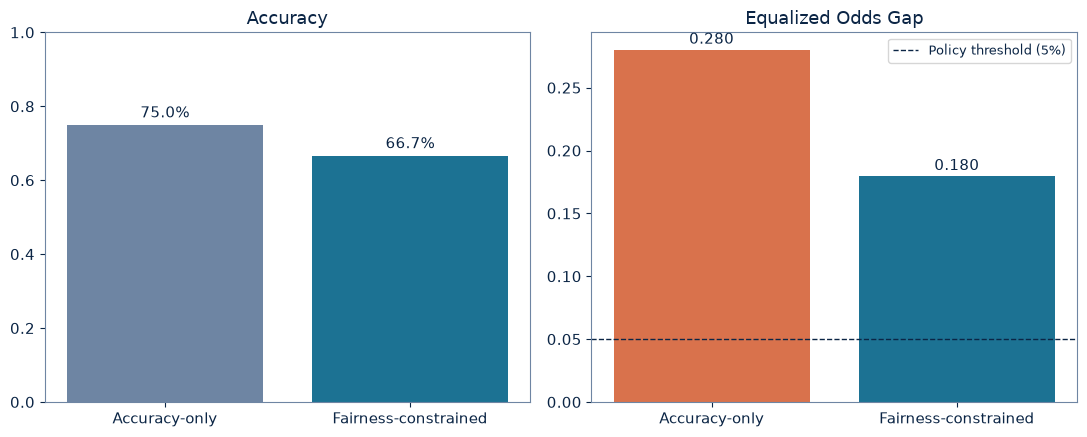


This is the accuracy-vs-fairness trade-off from the case study, reproduced on real data:
the fairness-constrained retrain accepts a small accuracy change in exchange for a smaller gap.


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))  # one canvas holding two charts side by side
approaches = ["Accuracy-only", "Fairness-constrained"]  # names for the two bars in each chart

axes[0].bar(approaches, [acc_accuracy_only, acc_after], color=[MUTED, TEAL])  # left chart: accuracy of each approach
axes[0].set_title("Accuracy")  # left chart title
axes[0].set_ylim(0, 1)  # y-axis from 0 to 1 (0% to 100%)
for i, v in enumerate([acc_accuracy_only, acc_after]):  # loop over each bar (i = position, v = value)
    axes[0].text(i, v + 0.02, f"{v:.1%}", ha="center")  # write the percentage just above the bar

axes[1].bar(approaches, [eo_gap_accuracy_only, eo_gap_after], color=[ALERT, TEAL])  # right chart: fairness gap of each approach
axes[1].axhline(0.05, color=NAVY, linestyle="--", linewidth=1, label="Policy threshold (5%)")  # dashed horizontal line at 0.05, our policy limit
axes[1].set_title("Equalized Odds Gap")  # right chart title
axes[1].legend(fontsize=9)  # show the key for the dashed line
for i, v in enumerate([eo_gap_accuracy_only, eo_gap_after]):  # loop over each bar
    axes[1].text(i, v + 0.005, f"{v:.3f}", ha="center")  # write the gap value just above the bar

plt.tight_layout()  # tidy spacing
plt.show()  # draw the charts

print()  # blank line for readability
print("This is the accuracy-vs-fairness trade-off from the case study, reproduced on real data:")  # takeaway line 1
print("the fairness-constrained retrain accepts a small accuracy change in exchange for a smaller gap.")  # takeaway line 2

**How to read the result**
- **Left chart:** the fairness-constrained model has lower accuracy.
- **Right chart:** its gap is lower, but its bar is **still above the dashed policy line**.
- The closing message in the code says "a small accuracy change". In our run the change is about 8 to 9 points, which is not small. The honest summary is: **fairness constraints buy a smaller gap at a real accuracy cost, and a human must decide whether that trade is acceptable.**

---
## 4.4 — Interactive: exploring the threshold trade-off

### 🎯 The idea
A model outputs a **probability** (for example, "63 % likely to be high progression"). To turn that into a yes/no decision you pick a **threshold**: *"say yes if the probability is at least this number."* Moving the threshold changes both accuracy and fairness. This demo lets you **see that live**.

### Step 1: Build the slider

**What we will do**
1. Get the accuracy-only model's **probabilities** for the holdout patients.
2. Write a function that, for any threshold, computes accuracy and the equalized odds gap and draws them as bars.
3. Attach it to a **slider** from 0.1 to 0.9. Drag it and the chart updates.

**The code**

In [35]:
import ipywidgets as widgets  # library for interactive controls such as sliders
from IPython.display import display  # helper for showing interactive items in a notebook

probs_holdout = accuracy_only_model.predict_proba(X_month6_holdout)[:, 1]  # each holdout patient's probability of "high progression" (column 1 = the "yes" class)

def explore_threshold(threshold=0.5):  # function that redraws the chart for any chosen threshold
    preds = (probs_holdout >= threshold).astype(int)  # turn probabilities into yes (1) / no (0) using the threshold
    acc = accuracy_score(y_month6_holdout, preds)  # accuracy at this threshold
    gap = equalized_odds_difference(y_month6_holdout, preds, sensitive_features=sex_holdout)  # fairness gap at this threshold
    bar_color = TEAL if gap <= 0.05 else ALERT  # gap bar is teal if within policy (5%), orange if above
    fig, ax = plt.subplots(figsize=(6.5, 3.5))  # create a small chart canvas
    ax.barh(["Accuracy", "Equalized odds gap"], [acc, gap], color=[TEAL, bar_color])  # two horizontal bars: accuracy and gap
    ax.set_xlim(0, 1)  # x-axis from 0 to 1
    ax.axvline(0.05, color=NAVY, linestyle="--", linewidth=1)  # dashed vertical line at the 0.05 policy threshold
    ax.set_title(f"Decision threshold = {threshold:.2f}")  # show the current threshold in the title
    for i, v in enumerate([acc, gap]):  # loop over each bar
        ax.text(v + 0.02, i, f"{v:.3f}", va="center")  # write each value just to the right of its bar
    plt.tight_layout()  # tidy spacing
    plt.show()  # draw the chart

widgets.interact(explore_threshold, threshold=widgets.FloatSlider(value=0.5, min=0.1, max=0.9, step=0.05));  # create the slider (starts at 0.5, ranges 0.1 to 0.9 in steps of 0.05) and link it to the function

interactive(children=(FloatSlider(value=0.5, description='threshold', max=0.9, min=0.1, step=0.05), Output()),…

**How to read the result**
Drag the slider and watch the two bars. In our run (approximate values):

| Threshold | Accuracy | Equalized odds gap |
|---|---|---|
| 0.1 or 0.3 | about 0.58 | 0.00 |
| 0.5 | about **0.75** | about **0.28** |
| 0.7 | about 0.43 | about 0.03 |
| 0.9 | about 0.42 | 0.00 |

🎓 **The big lesson:** a gap of 0 looks perfect, but at the extreme thresholds the model is simply **saying the same answer for nearly everybody**. It is "equally wrong for everyone", with low usefulness. At threshold 0.7 the gap is under the 0.05 policy line, yet accuracy is below a coin flip.

**A fairness number must never be read alone.** Always look at it together with accuracy, and ask whether the model is still doing a useful job.

> ℹ️ The slider only works in a live Jupyter / Colab session. In a static preview you will only see the starting view.

### Block 4 recap
| Stage | What we saw |
|---|---|
| Drift | Accuracy fell from about 0.68 to about 0.55 on the older population |
| Early warning | PSI flagged significant shift for both BMI and blood pressure |
| Hidden cost | The two groups were not served equally on drifted data (gap about 0.13) |
| Fix | A fairness-constrained retrain cut the gap substantially (0.28 → about 0.15 to 0.18) |
| Price | Accuracy dropped about 8 to 9 points, and the gap is still above the 5 % policy line |
| Caution | Extreme thresholds make the gap look perfect while the model becomes useless |

---
## Summary

Each block demonstrated concrete techniques on real data:

1. **Model Security:** an extraction attack, membership inference, data poisoning, OOD detection and a query-rate anomaly detector, with one demo per threat bucket
2. **Data Privacy:** quantified re-identification risk before and after anonymisation, and its utility cost
3. **Responsible AI:** a fairness gap hidden inside a good aggregate accuracy number, explained locally (one prediction) and globally (overall feature importance) with SHAP
4. **Case Study:** drift detection, a fairness gap that drift can introduce, and a constrained retrain with its trade-offs

### Five ideas to remember
1. **A model is an attack surface.** Accuracy alone does not mean "safe".
2. **Removing names is not anonymisation.** Combinations of ordinary details can identify people.
3. **One good average can hide an unfair split.** Always slice metrics by group.
4. **Explanations help you ask better questions.** They show what the model relies on, not proof of cause.
5. **Models age.** Monitor for drift continuously and re-check fairness after every change.

These are teaching-scale demonstrations. Production systems need continuous monitoring pipelines, not one-off notebook runs, but the underlying techniques are the same ones used in practice.

---